# Clasificación de países con ResNet18 desde cero

Entrenamos **ResNet18**, una CNN con conexiones residuales, con pesos
aleatorios (`weights=None`), sin congelar capas. La salida tiene una clase por país.
Cada experimento carga train de su muestra y usa la misma validación global:
`datasets/samples/data/validation.parquet`. No generamos otra partición.

Orden: **1. Configuración y datos → 2. Entrenamiento y curvas de loss →
3. Métricas sobre validación**.


## 1. Configuración y datos

In [5]:
from pathlib import Path
from datetime import datetime
import json
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from datasets import Dataset as HFDataset, Image as HFImage
from PIL import Image
from io import BytesIO
from sklearn.metrics import accuracy_score, confusion_matrix
from tqdm.auto import tqdm
from IPython.display import display

# Rutas absolutas o relativas a la raíz del proyecto.
RUTA_SAMPLE = "datasets/samples/muestra_n-20000_umbral-csv-1000_balanceado_paises-71_seed-42_solo-train"
RUTA_VALIDACION = "datasets/samples/data/validation/validation.parquet"
# Corrida nueva. Para continuar una corrida, REANUDAR=True y RUTA_RESULTADOS con su carpeta.
REANUDAR = False
RUTA_RESULTADOS = None
EPOCAS = 30  # Total de épocas, incluyendo las ya completadas.
BATCH_SIZE = 4
ACUMULAR_BATCHES = 8  # Batch efectivo: 4 * 8 = 32 imágenes.
LEARNING_RATE = 0.0001
WEIGHT_DECAY = 5e-4
PACIENCIA = 5  # Early stopping según loss de validación.
TAMANO_IMAGEN = 224
NUM_WORKERS = 0  # Compatible con notebooks en Windows.
SEMILLA = 42
USAR_AMP = True  # Precisión mixta solo con CUDA.
DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"

raiz = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "pyproject.toml").is_file()), None)
if raiz is None:
    raise FileNotFoundError("Ejecutá el notebook dentro del proyecto.")
def resolver_ruta(ruta):
    p = Path(ruta).expanduser()
    return (p if p.is_absolute() else raiz / p).resolve()

ruta_sample = resolver_ruta(RUTA_SAMPLE)
if not (ruta_sample / "COMPLETO").is_file():
    raise FileNotFoundError(f"Falta el marcador COMPLETO en {ruta_sample}.")
config_sample = json.loads((ruta_sample / "config.json").read_text(encoding="utf-8"))
archivos = {
    "train": ruta_sample / config_sample["archivos_salida"]["train"],
    "validation": resolver_ruta(RUTA_VALIDACION),
}
for archivo in archivos.values():
    if not archivo.is_file():
        raise FileNotFoundError(archivo)
assert EPOCAS >= 1 and BATCH_SIZE >= 1 and ACUMULAR_BATCHES >= 1
assert PACIENCIA >= 1 and TAMANO_IMAGEN >= 32 and NUM_WORKERS >= 0
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEMILLA)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
device = torch.device(DISPOSITIVO)
amp_activo = USAR_AMP and device.type == "cuda"
ruta_resultados = (resolver_ruta(RUTA_RESULTADOS) if RUTA_RESULTADOS else
                   raiz / "outputs" / "resnet18" / datetime.now().strftime("%Y%m%d_%H%M%S_%f"))
print(f"Sample: {ruta_sample}\nResultados: {ruta_resultados}\nDispositivo: {device}")
if device.type == "cuda":
    print(torch.cuda.get_device_name(device))

Sample: C:\Users\jurad\Documents\facultad\rrnn2\tp-final\geo-project\datasets\samples\muestra_n-20000_umbral-csv-1000_balanceado_paises-71_seed-42_solo-train
Resultados: c:\Users\jurad\Documents\facultad\rrnn2\tp-final\geo-project\outputs\resnet18\20261024_115023_590785
Dispositivo: cuda
NVIDIA GeForce GTX 1650 SUPER


### Carga y controles de separación

La caché Arrow se guarda en `.cache/modeling/`; las imágenes se decodifican al
solicitarlas, sin cargar todas las imágenes RGB en RAM. Se verifica que no haya
`panoid` compartidos ni países de validación ausentes en entrenamiento.
El vocabulario de clases se construye únicamente con train (incluye `NA`, Namibia).

In [6]:
datos = {
    split: HFDataset.from_parquet(str(archivo), cache_dir=str(raiz / ".cache/modeling/hf"))
        .cast_column("image", HFImage(decode=False))
    for split, archivo in archivos.items()
}
def metadatos(dataset):
    tabla = dataset.select_columns(["country_code", "panoid", "image_id"]).to_pandas()
    if tabla.isna().any().any():
        raise ValueError("Hay países o identificadores faltantes en el sample.")
    tabla["country_code"] = tabla["country_code"].str.strip().str.upper()
    if (tabla["country_code"] == "").any():
        raise ValueError("Hay códigos de país vacíos.")
    return tabla

meta_train, meta_val = (metadatos(datos[s]) for s in ("train", "validation"))
if not len(meta_train) or not len(meta_val):
    raise ValueError("Ambos splits deben contener imágenes.")
for columna in ("panoid", "image_id"):
    if set(meta_train[columna]) & set(meta_val[columna]):
        raise ValueError(f"Fuga de datos: {columna} compartidos entre splits.")
paises = sorted(meta_train["country_code"].unique().tolist())
pais_a_idx = {pais: i for i, pais in enumerate(paises)}
desconocidos = set(meta_val["country_code"]) - set(paises)
if desconocidos:
    raise ValueError(f"Países de validación sin train: {desconocidos}")
display(pd.DataFrame({
    "train": meta_train["country_code"].value_counts(),
    "validation": meta_val["country_code"].value_counts(),
}).fillna(0).astype(int).sort_index())
print(f"Train: {len(meta_train):,}; validación: {len(meta_val):,}; países: {len(paises)}")

Generating train split: 20000 examples [00:26, 751.41 examples/s] 
Generating train split: 5332 examples [00:06, 870.09 examples/s] 


,train,validation
country_code,,
AR,282,76
AT,282,24
AU,282,156
BA,282,20
BD,282,32
...,...,...
UA,281,20
US,281,1204
UY,281,20


Train: 20,000; validación: 5,332; países: 71


### Convención de continentes

Agrupación explícita y editable de seis continentes: América del Norte incluye
Centroamérica y el Caribe. Rusia se asigna a Europa; Turquía y Kazajistán a Asia.
Se verifica la cobertura de todos los países del sample; un país nuevo requiere
agregar su código a esta tabla antes de entrenar.

In [7]:
GRUPOS_CONTINENTES = {
    "África": "BW GH KE NA NG SN ZA",
    "América del Norte": "CA CR MX US",
    "América del Sur": "AR BO BR CL CO EC PE PY UY",
    "Asia": "BD ID IN JP KH KR KZ LK MN MY NP OM PH TH TR TW VN",
    "Europa": "AT BA BE BG CH CZ DE DK EE ES FI FR GB GR HR HU IE IS IT LT LV NL NO PL PT RO RS RU SE SI SK UA",
    "Oceanía": "AU NZ",
}
pais_a_continente = {pais: continente
                     for continente, codigos in GRUPOS_CONTINENTES.items()
                     for pais in codigos.split()}
sin_continente = set(paises) - set(pais_a_continente)
if sin_continente:
    raise ValueError(f"Completá GRUPOS_CONTINENTES para: {sorted(sin_continente)}")
continentes = sorted({pais_a_continente[p] for p in paises})

In [8]:
# Escala fija [-1, 1]; no se utilizan pesos ni estadísticas aprendidas de otro dataset.
transform_train = transforms.Compose([
    transforms.Resize(TAMANO_IMAGEN),
    transforms.CenterCrop(TAMANO_IMAGEN),
    transforms.ToTensor(),
    transforms.Normalize((0.5,) * 3, (0.5,) * 3),
])
transform_val = transforms.Compose([
    transforms.Resize(TAMANO_IMAGEN),
    transforms.CenterCrop(TAMANO_IMAGEN),
    transforms.ToTensor(),
    transforms.Normalize((0.5,) * 3, (0.5,) * 3),
])

class ImagenesPaises(Dataset):
    def __init__(self, datos, etiquetas, transform):
        self.datos = datos
        self.etiquetas = etiquetas["country_code"].map(pais_a_idx).to_numpy(dtype=np.int64)
        self.transform = transform

    def __len__(self):
        return len(self.datos)

    def __getitem__(self, idx):
        contenido = self.datos[int(idx)]["image"]
        if contenido.get("bytes") is not None:
            fuente = BytesIO(contenido["bytes"])
        else:
            fuente = resolver_ruta(contenido["path"])
        with Image.open(fuente) as imagen:
            tensor = self.transform(imagen.convert("RGB"))
        return tensor, int(self.etiquetas[idx])

dataset_train = ImagenesPaises(datos["train"], meta_train, transform_train)
dataset_val = ImagenesPaises(datos["validation"], meta_val, transform_val)
loader_train = DataLoader(dataset_train, batch_size=BATCH_SIZE, shuffle=True,
                          generator=torch.Generator().manual_seed(SEMILLA),
                          num_workers=NUM_WORKERS, pin_memory=device.type == "cuda")
loader_val = DataLoader(dataset_val, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=device.type == "cuda")

## 2. Fase de entrenamiento

ResNet18 con inicialización aleatoria y todas las capas entrenables.
Optimizador Adam, reducción de learning rate y early stopping según loss de
validación. Train y validación usan el mismo preprocesamiento determinista,
sin aumentación. La loss de train se mide en modo entrenamiento y la de
validación en modo evaluación; BatchNorm utiliza estadísticas del batch en train
y las estadísticas acumuladas en validación. Ambas losses son promedios por imagen.

Se guarda el modelo de **menor loss de validación**, el historial y la configuración.
Cada ejecución usa su propia carpeta. Si hay falta de memoria, reducir `BATCH_SIZE`
y aumentar `ACUMULAR_BATCHES` para conservar el batch efectivo.

### Continuar después de reiniciar el kernel

La configuración ya apunta a la corrida interrumpida. Ejecutar las secciones 1 y 2
en orden: se reconstruyen datos y modelo antes de cargar el checkpoint. `EPOCAS`
es el total objetivo (30): al recuperar la época 9 se continúa desde la **10**.

- `ultimo_entrenamiento.pt`: estado al terminar la última época completa, con
  modelo, Adam, scheduler, GradScaler, historial, early stopping y estados aleatorios
  de Python, NumPy, PyTorch, CUDA y el generador del DataLoader.
- `mejor_resnet18.pt`: pesos del modelo de menor loss de validación, para métricas.

Se prefiere el último checkpoint completo. Si solo existe el checkpoint antiguo de
pesos, se recuperan sus pesos y el historial hasta esa época; **Adam y el scheduler
comienzan nuevos**. Esto ocurre en la primera continuación de esta corrida.

Los guardados se reemplazan de forma atómica: una escritura interrumpida no pisa
el checkpoint anterior. Se recupera desde el **final de una época**, no desde un
batch intermedio. Para reproducir la secuencia se debe conservar la configuración,
el entorno y el dispositivo; se controla su compatibilidad antes de cargar estados.
Con `NUM_WORKERS=0` se conserva también la secuencia de carga y transformaciones.
Para una corrida nueva, usar `REANUDAR=False` y `RUTA_RESULTADOS=None`.


In [9]:
modelo = models.resnet18(weights=None, num_classes=len(paises)).to(device)
criterio = nn.CrossEntropyLoss()
optimizador = torch.optim.Adam(modelo.parameters(), lr=LEARNING_RATE,
                               weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizador, factor=0.1, patience=2)
scaler = torch.amp.GradScaler("cuda", enabled=amp_activo)
print(f"Parámetros entrenables: {sum(p.numel() for p in modelo.parameters() if p.requires_grad):,}")

def ejecutar_epoca(modelo, loader, entrenar):
    modelo.train(entrenar)
    total_loss, total = 0.0, 0
    if entrenar:
        optimizador.zero_grad(set_to_none=True)
    with torch.set_grad_enabled(entrenar):
        for paso, (imagenes, etiquetas) in enumerate(tqdm(loader, desc="Train" if entrenar else "Validación")):
            imagenes = imagenes.to(device, non_blocking=True)
            etiquetas = etiquetas.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, enabled=amp_activo):
                logits = modelo(imagenes)
                loss = criterio(logits, etiquetas)
            n = etiquetas.size(0)
            if entrenar:
                # Ponderar por imágenes, incluso en el último grupo incompleto.
                inicio_grupo = (paso // ACUMULAR_BATCHES) * ACUMULAR_BATCHES
                n_grupo = min(ACUMULAR_BATCHES * loader.batch_size,
                              len(loader.dataset) - inicio_grupo * loader.batch_size)
                scaler.scale(loss * n / n_grupo).backward()
                if (paso + 1) % ACUMULAR_BATCHES == 0 or paso + 1 == len(loader):
                    scaler.step(optimizador)
                    scaler.update()
                    optimizador.zero_grad(set_to_none=True)
            total_loss += loss.detach().item() * n
            total += n
    return total_loss / total

Parámetros entrenables: 11,212,935


In [10]:
def guardar_checkpoint(estado, destino):
    """No reemplazar un archivo válido hasta completar la escritura."""
    temporal = destino.with_name(destino.name + ".tmp")
    torch.save(estado, temporal)
    temporal.replace(destino)


def capturar_azar():
    estado_np = np.random.get_state()
    return {
        "python": random.getstate(),
        "numpy": {"generador": estado_np[0], "claves": estado_np[1].tolist(),
                  "posicion": int(estado_np[2]), "gauss": int(estado_np[3]),
                  "cache_gauss": float(estado_np[4])},
        "torch_cpu": torch.get_rng_state(),
        "torch_cuda": torch.cuda.get_rng_state_all() if device.type == "cuda" else [],
        "loader_train": loader_train.generator.get_state(),
    }


def restaurar_azar(estado):
    random.setstate(estado["python"])
    s = estado["numpy"]
    np.random.set_state((s["generador"], np.asarray(s["claves"], dtype=np.uint32),
                         s["posicion"], s["gauss"], s["cache_gauss"]))
    torch.set_rng_state(estado["torch_cpu"])
    if device.type == "cuda":
        if len(estado["torch_cuda"]) != torch.cuda.device_count():
            raise ValueError("Cambió la cantidad de GPUs; no se puede restaurar el estado CUDA.")
        torch.cuda.set_rng_state_all(estado["torch_cuda"])
    loader_train.generator.set_state(estado["loader_train"])


def validar_config_reanudacion(guardada, actual, completa):
    claves = ["arquitectura", "paises", "pais_a_continente", "tamano_imagen",
              "batch_size", "acumular_batches", "learning_rate", "optimizador",
              "weight_decay", "paciencia", "semilla", "filas_train", "filas_validation"]
    if completa:
        claves += ["amp", "torch", "dispositivo", "num_workers", "archivos_sample",
                   "preprocesamiento_train", "preprocesamiento_val"]
    diferencias = [k for k in claves if guardada.get(k) != actual.get(k)]
    if Path(guardada["ruta_sample"]).resolve() != Path(actual["ruta_sample"]).resolve():
        diferencias.append("ruta_sample")
    if diferencias:
        raise ValueError(f"Configuración distinta a la del checkpoint: {diferencias}")


def guardar_historial(historial):
    destino = ruta_resultados / "historial.csv"
    temporal = destino.with_name(destino.name + ".tmp")
    pd.DataFrame(historial).to_csv(temporal, index=False)
    temporal.replace(destino)

In [11]:
ruta_checkpoint = ruta_resultados / "mejor_resnet18.pt"
ruta_ultimo = ruta_resultados / "ultimo_entrenamiento.pt"
config_entrenamiento = {
    "arquitectura": "resnet18", "weights": None, "ruta_sample": str(ruta_sample),
    "epocas_maximas": EPOCAS, "batch_size": BATCH_SIZE, "acumular_batches": ACUMULAR_BATCHES,
    "learning_rate": LEARNING_RATE, "optimizador": "Adam", "weight_decay": WEIGHT_DECAY,
    "paciencia": PACIENCIA, "tamano_imagen": TAMANO_IMAGEN, "semilla": SEMILLA,
    "amp": amp_activo, "paises": paises, "pais_a_continente": pais_a_continente,
    "filas_train": len(dataset_train), "filas_validation": len(dataset_val),
    "torch": str(torch.__version__), "dispositivo": str(device), "num_workers": NUM_WORKERS,
    "preprocesamiento_train": repr(transform_train), "preprocesamiento_val": repr(transform_val),
    "archivos_sample": {s: {"bytes": p.stat().st_size, "mtime_ns": p.stat().st_mtime_ns}
                        for s, p in archivos.items()},
}
historial = []
mejor_loss, sin_mejora, epoca_inicio = float("inf"), 0, 1

if REANUDAR:
    origen = ruta_ultimo if ruta_ultimo.is_file() else ruta_checkpoint
    if not origen.is_file():
        raise FileNotFoundError(f"No hay checkpoint para continuar en {ruta_resultados}")
    estado = torch.load(origen, map_location="cpu", weights_only=True)
    completa = "optimizer_state_dict" in estado
    validar_config_reanudacion(estado["config"], config_entrenamiento, completa)
    modelo.load_state_dict(estado["model_state_dict"])
    epoca_guardada = int(estado["epoca"])
    epoca_inicio = epoca_guardada + 1
    if completa:
        optimizador.load_state_dict(estado["optimizer_state_dict"])
        scheduler.load_state_dict(estado["scheduler_state_dict"])
        scaler.load_state_dict(estado["scaler_state_dict"])
        historial = estado["historial"]
        mejor_loss = float(estado["mejor_loss"])
        sin_mejora = int(estado["sin_mejora"])
        restaurar_azar(estado["azar"])
        print(f"Estado completo recuperado de época {epoca_guardada}.")
    else:
        # El formato anterior solo conservaba pesos, época, loss y configuración.
        historial_previo = pd.read_csv(ruta_resultados / "historial.csv")
        historial = historial_previo.loc[historial_previo["epoca"] <= epoca_guardada].to_dict("records")
        if [int(f["epoca"]) for f in historial] != list(range(1, epoca_guardada + 1)):
            raise ValueError("El historial antiguo no contiene todas las épocas del checkpoint.")
        if not np.isclose(historial[-1]["loss_validation"], estado["loss_validation"]):
            raise ValueError("La loss del checkpoint no coincide con su fila del historial.")
        mejor_loss = float(estado["loss_validation"])
        print(f"Pesos recuperados de época {epoca_guardada}. Adam, scheduler y GradScaler nuevos.")
        if len(historial_previo) > len(historial):
            print("Las épocas posteriores al checkpoint no se retoman; no se conservaron sus pesos.")
    if len(historial) != epoca_guardada or int(historial[-1]["epoca"]) != epoca_guardada:
        raise ValueError("El historial no coincide con la época del checkpoint.")
    del estado
    print(f"Próxima época: {epoca_inicio}; total objetivo: {EPOCAS}.")
else:
    if any((ruta_resultados / nombre).exists() for nombre in
           ("mejor_resnet18.pt", "ultimo_entrenamiento.pt", "historial.csv", "config_entrenamiento.json")):
        raise FileExistsError("La carpeta ya contiene una corrida. Usá REANUDAR=True u otra carpeta.")
    ruta_resultados.mkdir(parents=True, exist_ok=True)
    (ruta_resultados / "config_entrenamiento.json").write_text(
        json.dumps(config_entrenamiento, ensure_ascii=False, indent=2), encoding="utf-8")

In [12]:
if epoca_inicio > EPOCAS:
    print(f"Ya se completaron {epoca_inicio - 1} épocas; no hay épocas nuevas para ejecutar.")
for epoca in range(epoca_inicio, EPOCAS + 1):
    if sin_mejora >= PACIENCIA:
        print(f"Early stopping ya alcanzado: {PACIENCIA} épocas sin mejora.")
        break
    inicio = time.perf_counter()
    lr = optimizador.param_groups[0]["lr"]
    loss_train = ejecutar_epoca(modelo, loader_train, entrenar=True)
    loss_val = ejecutar_epoca(modelo, loader_val, entrenar=False)
    if not np.isfinite([loss_train, loss_val]).all():
        raise RuntimeError("Loss no finita. El checkpoint anterior sigue disponible.")
    historial.append({"epoca": epoca, "loss_train": loss_train, "loss_validation": loss_val,
                      "learning_rate": lr, "segundos": time.perf_counter() - inicio})
    if loss_val < mejor_loss:
        mejor_loss, sin_mejora = loss_val, 0
        guardar_checkpoint({"model_state_dict": modelo.state_dict(), "epoca": epoca,
                            "loss_validation": loss_val, "config": config_entrenamiento}, ruta_checkpoint)
    else:
        sin_mejora += 1
    scheduler.step(loss_val)
    # Checkpoint completo después del scheduler y antes de comenzar otra época.
    guardar_checkpoint({
        "version": 1, "model_state_dict": modelo.state_dict(), "epoca": epoca,
        "loss_validation": loss_val, "config": config_entrenamiento,
        "optimizer_state_dict": optimizador.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(), "scaler_state_dict": scaler.state_dict(),
        "mejor_loss": mejor_loss, "sin_mejora": sin_mejora,
        "historial": historial, "azar": capturar_azar(),
    }, ruta_ultimo)
    # El historial del checkpoint es la fuente de recuperación si se interrumpe el CSV.
    guardar_historial(historial)
    print(f"Época {epoca}/{EPOCAS} | train={loss_train:.4f} | val={loss_val:.4f} | lr={lr:.5g}")
    if sin_mejora >= PACIENCIA:
        print(f"Early stopping: {PACIENCIA} épocas sin mejora.")
        break
print(f"Mejor loss de validación: {mejor_loss:.4f}; checkpoint: {ruta_checkpoint}")

Validación: 100%|██████████| 1333/1333 [01:10<00:00, 18.97it/s]


Época 1/30 | train=3.8273 | val=3.5588 | lr=0.0001


Validación: 100%|██████████| 1333/1333 [01:03<00:00, 20.88it/s]


Época 2/30 | train=3.4930 | val=3.7397 | lr=0.0001


Validación: 100%|██████████| 1333/1333 [01:04<00:00, 20.83it/s]


...

Época 17/30 | train=1.0223 | val=2.8652 | lr=1e-05


Validación: 100%|██████████| 1333/1333 [01:03<00:00, 20.96it/s]


Época 18/30 | train=0.9523 | val=2.8409 | lr=1e-06


Validación: 100%|██████████| 1333/1333 [01:03<00:00, 20.96it/s]


Época 19/30 | train=0.9361 | val=2.9411 | lr=1e-06
Early stopping: 5 épocas sin mejora.
Mejor loss de validación: 2.8161; checkpoint: c:\Users\jurad\Documents\facultad\rrnn2\tp-final\geo-project\outputs\resnet18\20261024_115023_590785\mejor_resnet18.pt


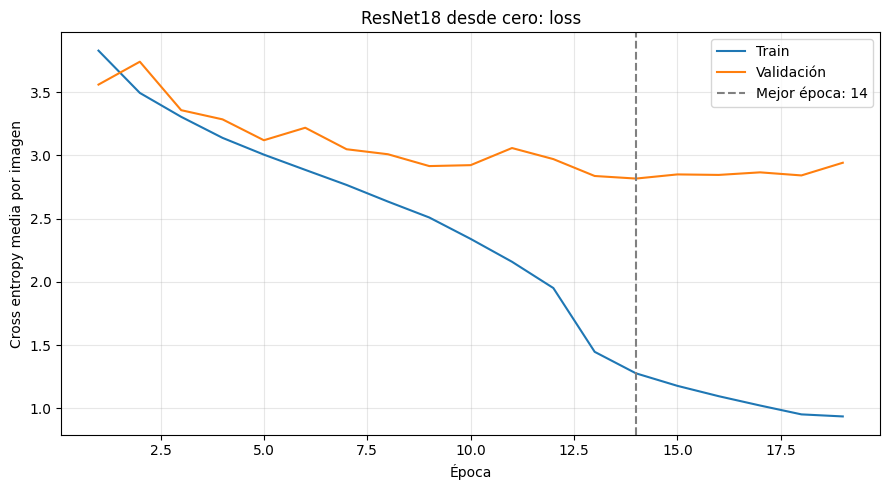

In [13]:
historia = (pd.DataFrame(historial) if "historial" in globals() and historial
            else pd.read_csv(ruta_resultados / "historial.csv"))
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(historia["epoca"], historia["loss_train"], label="Train")
ax.plot(historia["epoca"], historia["loss_validation"], label="Validación")
mejor_epoca = int(historia.loc[historia["loss_validation"].idxmin(), "epoca"])
ax.axvline(mejor_epoca, color="gray", linestyle="--", label=f"Mejor época: {mejor_epoca}")
ax.set(xlabel="Época", ylabel="Cross entropy media por imagen", title="ResNet18 desde cero: loss")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(ruta_resultados / "curvas_loss.png", dpi=160)
plt.show()

## 3. Métricas sobre validación

Esta fase carga el mejor checkpoint y evalúa **todo el conjunto de validación**,
sin gradientes y con BatchNorm en modo evaluación. Para repetirla sin entrenar, indicar
`RUTA_RESULTADOS` de una ejecución previa, ejecutar la sección 1 y luego esta sección.
El tamaño de imagen y el sample deben coincidir con los del checkpoint.

Reportamos accuracy de país global, accuracy de país por continente real y
accuracy de continente (se toma el continente del país predicho por argmax).
Las matrices incluyen país × país, continente × continente y una matriz de países
por cada continente. Como validación también selecciona el checkpoint, estos
resultados no son una estimación final sobre un conjunto de test independiente.

In [14]:
ruta_checkpoint = ruta_resultados / "mejor_resnet18.pt"
checkpoint = torch.load(ruta_checkpoint, map_location="cpu", weights_only=True)
config_guardada = checkpoint["config"]
if config_guardada["arquitectura"] != "resnet18":
    raise ValueError("El checkpoint no corresponde a ResNet18.")
if (config_guardada["paises"] != paises
        or Path(config_guardada["ruta_sample"]).resolve() != ruta_sample
        or config_guardada["tamano_imagen"] != TAMANO_IMAGEN
        or config_guardada["pais_a_continente"] != pais_a_continente):
    raise ValueError("Sample, clases, continentes o tamaño de imagen distintos del entrenamiento.")
# Liberar estados del optimizador si se acaba de entrenar, antes de evaluar.
if "optimizador" in globals():
    optimizador.state.clear()
if "modelo" not in globals():
    modelo = models.resnet18(weights=None, num_classes=len(paises)).to(device)
modelo.load_state_dict(checkpoint["model_state_dict"])
print(f"Evaluando checkpoint de época {checkpoint['epoca']} (loss={checkpoint['loss_validation']:.4f})")
del checkpoint
modelo.eval()
reales, predichos = [], []
with torch.inference_mode():
    for imagenes, etiquetas in tqdm(loader_val, desc="Métricas de validación"):
        with torch.autocast(device_type=device.type, enabled=amp_activo):
            logits = modelo(imagenes.to(device, non_blocking=True))
        reales.extend(etiquetas.numpy().tolist())
        predichos.extend(logits.argmax(dim=1).cpu().tolist())
y_true, y_pred = np.asarray(reales), np.asarray(predichos)
assert len(y_true) == len(dataset_val) == len(meta_val)
predicciones = meta_val[["image_id", "panoid", "country_code"]].copy()
predicciones = predicciones.rename(columns={"country_code": "pais_real"})
predicciones["pais_predicho"] = np.asarray(paises)[y_pred]
predicciones["continente_real"] = predicciones["pais_real"].map(pais_a_continente)
predicciones["continente_predicho"] = predicciones["pais_predicho"].map(pais_a_continente)
predicciones["acierto_pais"] = y_true == y_pred
predicciones["acierto_continente"] = (predicciones["continente_real"] == predicciones["continente_predicho"])
predicciones.to_csv(ruta_resultados / "predicciones_validation.csv", index=False)
accuracy_pais = accuracy_score(y_true, y_pred)
accuracy_continente = accuracy_score(predicciones["continente_real"], predicciones["continente_predicho"])
resumen_metricas = {"n_validation": len(y_true), "accuracy_pais": accuracy_pais,
                    "accuracy_continente": accuracy_continente}
print(f"Accuracy de país: {accuracy_pais:.2%}")
print(f"Accuracy de continente: {accuracy_continente:.2%}")
por_continente = predicciones.groupby("continente_real").agg(
    n=("acierto_pais", "size"), accuracy_pais=("acierto_pais", "mean"),
    accuracy_continente=("acierto_continente", "mean"))
display(por_continente.style.format({"accuracy_pais": "{:.2%}", "accuracy_continente": "{:.2%}"}))
por_continente.to_csv(ruta_resultados / "accuracy_por_continente.csv")
(ruta_resultados / "metricas_validation.json").write_text(
    json.dumps(resumen_metricas, ensure_ascii=False, indent=2), encoding="utf-8")

Evaluando checkpoint de época 14 (loss=2.8161)


Métricas de validación: 100%|██████████| 1333/1333 [01:02<00:00, 21.26it/s]


Accuracy de país: 26.93%
Accuracy de continente: 56.41%


,n,accuracy_pais,accuracy_continente
continente_real,,,
América del Norte,1500,13.60%,24.47%
América del Sur,580,32.24%,50.34%
Asia,1432,43.30%,73.74%
Europa,1460,18.22%,75.21%
Oceanía,180,32.78%,39.44%
África,180,55.56%,68.89%


110

### Matrices de confusión globales

Filas = clase real; columnas = clase predicha. Se muestran conteos y proporciones
normalizadas por fila (recall de cada clase en la diagonal). Los CSV conservan los
conteos y las figuras se guardan en la carpeta de resultados.

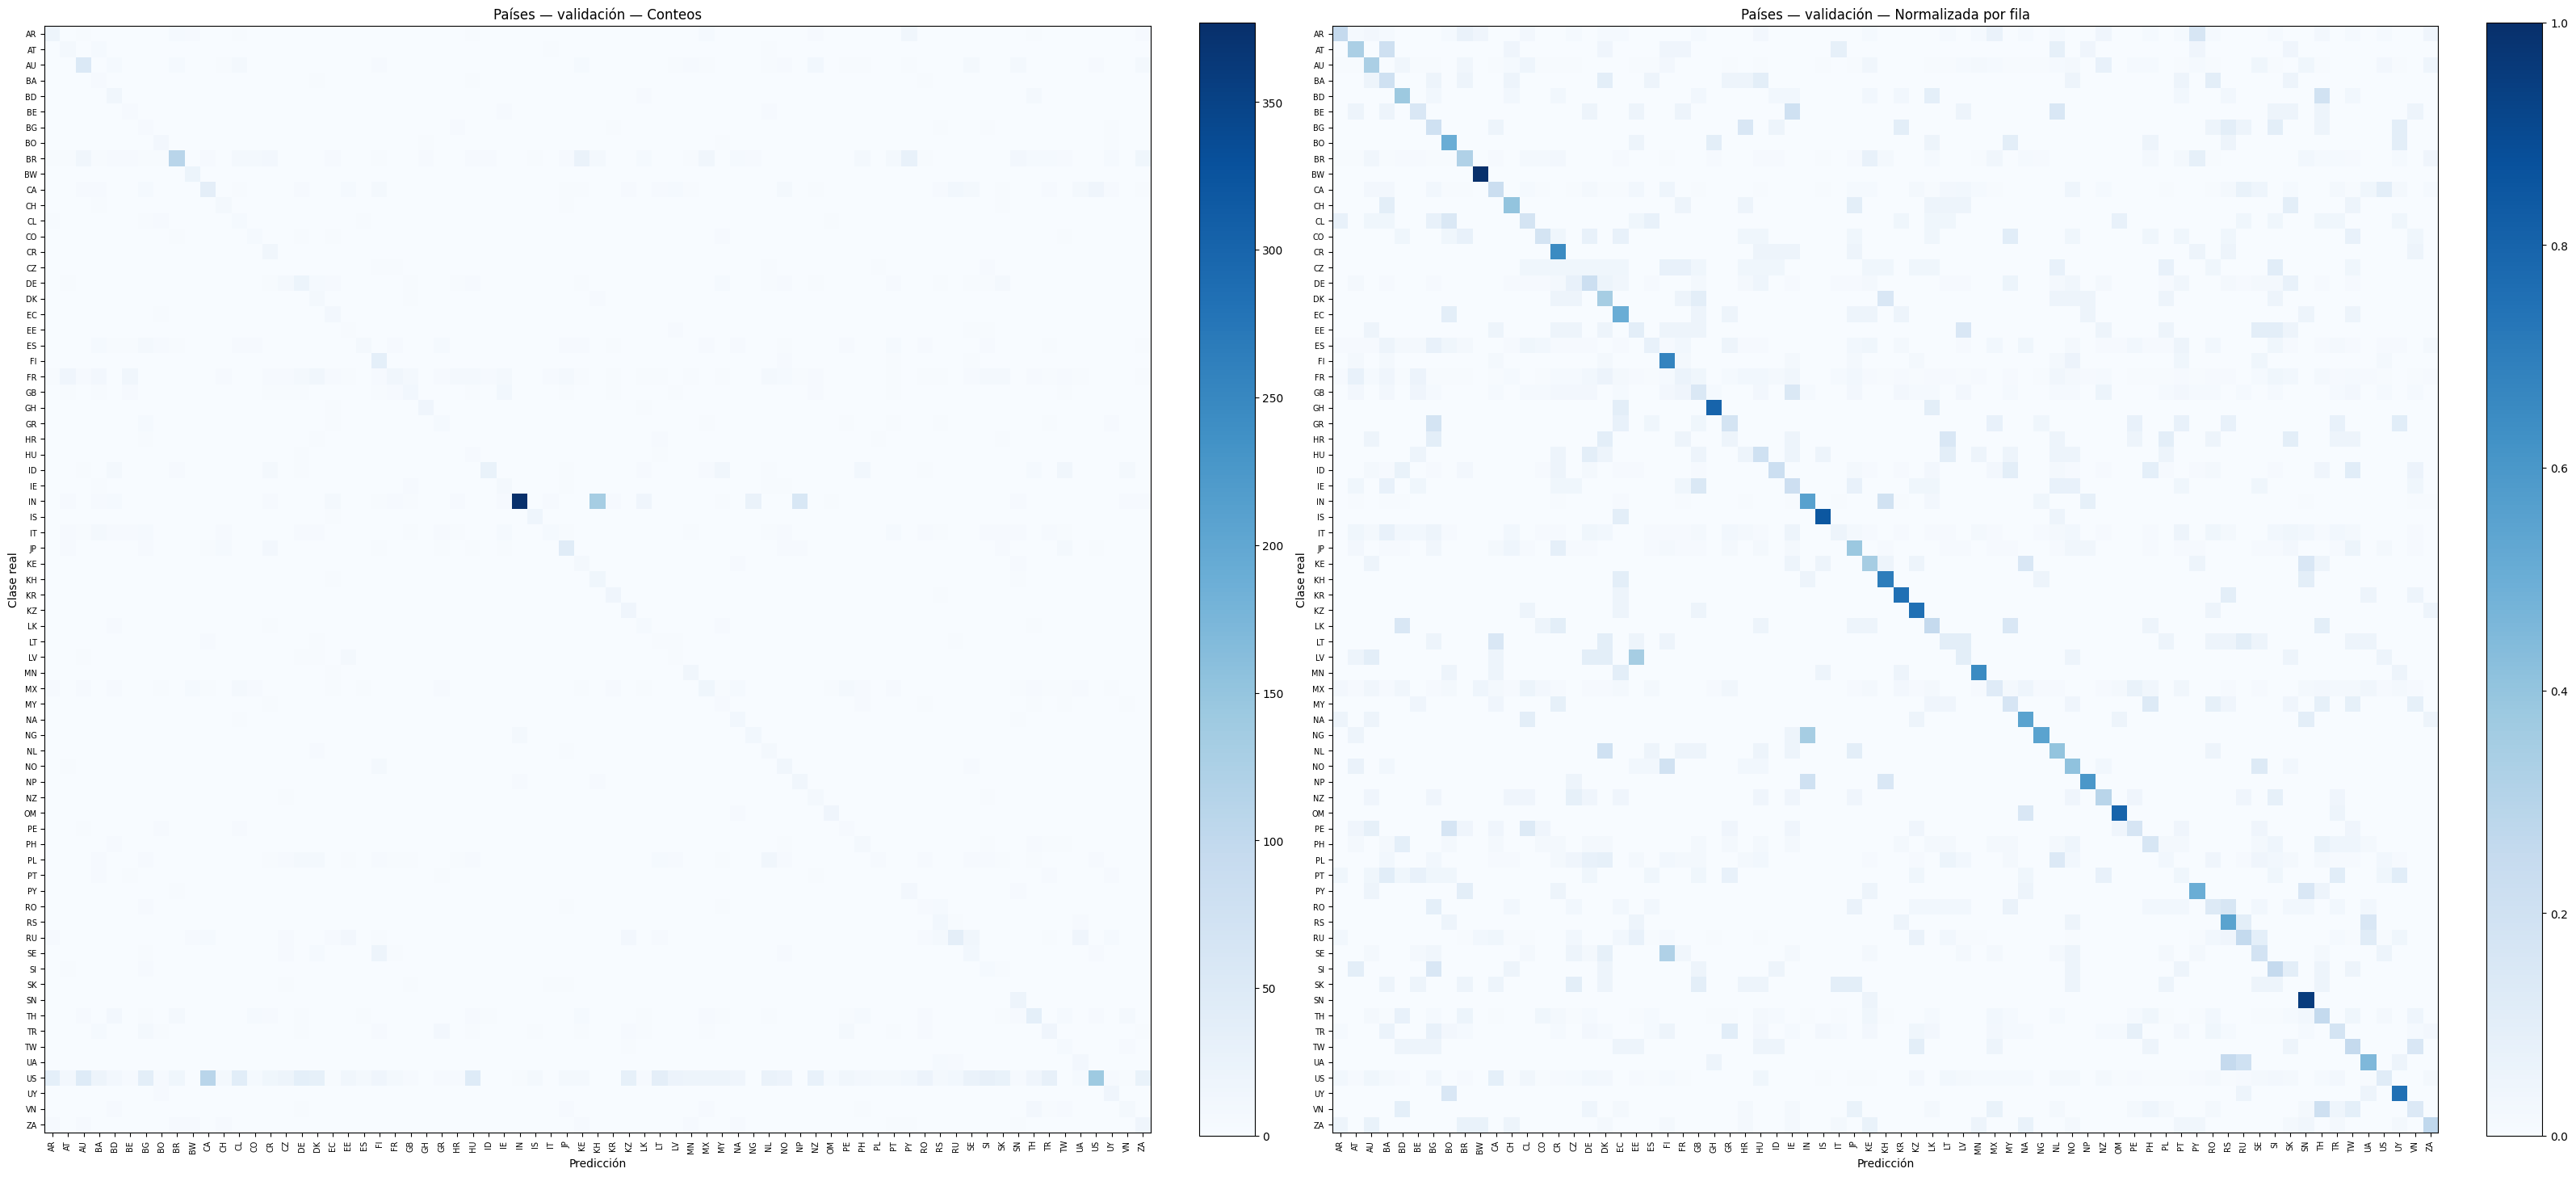

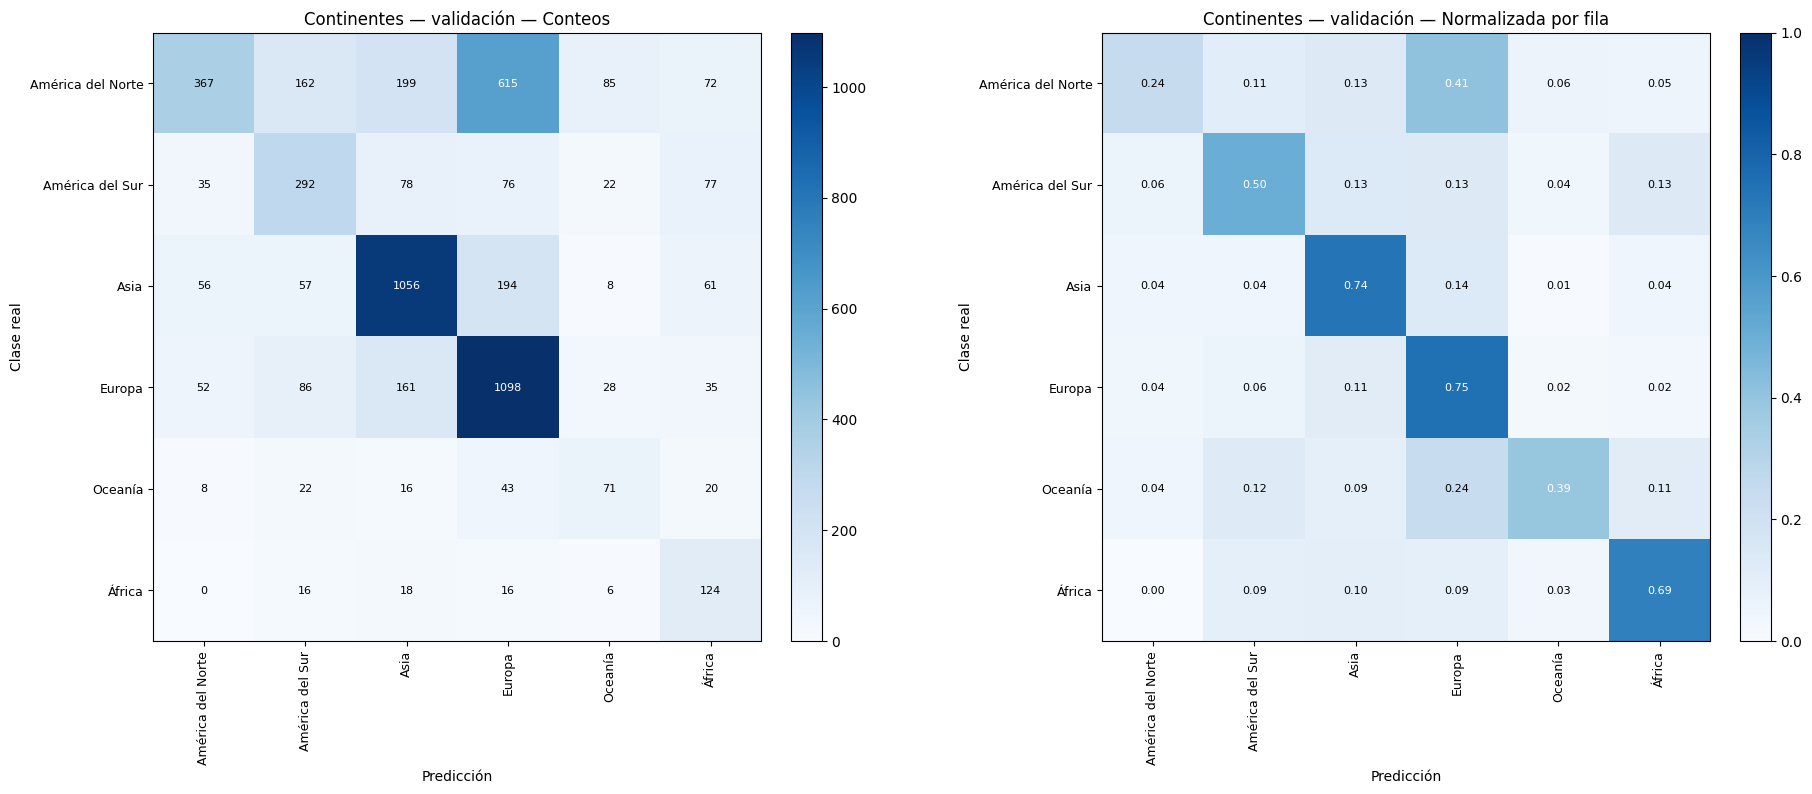

In [15]:
def mostrar_matriz(tabla, titulo, nombre, anotar=False):
    valores = tabla.to_numpy()
    normalizada = np.divide(valores, valores.sum(axis=1, keepdims=True),
                            out=np.zeros_like(valores, dtype=float),
                            where=valores.sum(axis=1, keepdims=True) != 0)
    tabla.to_csv(ruta_resultados / f"{nombre}.csv")
    pd.DataFrame(normalizada, index=tabla.index, columns=tabla.columns).to_csv(
        ruta_resultados / f"{nombre}_normalizada.csv")
    grande = max(tabla.shape) > 30
    fig, axes = plt.subplots(1, 2, figsize=(32, 15) if grande else (19, 8))
    for ax, matriz, subtitulo, formato in zip(
            axes, [valores, normalizada], ["Conteos", "Normalizada por fila"], ["d", ".2f"]):
        grafico = ax.imshow(matriz, cmap="Blues", vmin=0, vmax=1 if subtitulo.startswith("Normalizada") else None)
        ax.set_xticks(range(len(tabla.columns)), tabla.columns, rotation=90, fontsize=7 if grande else 9)
        ax.set_yticks(range(len(tabla.index)), tabla.index, fontsize=7 if grande else 9)
        ax.set(xlabel="Predicción", ylabel="Clase real", title=f"{titulo} — {subtitulo}")
        if anotar:
            umbral = matriz.max() / 2
            for i in range(matriz.shape[0]):
                for j in range(matriz.shape[1]):
                    ax.text(j, i, format(matriz[i, j], formato), ha="center", va="center",
                            color="white" if matriz[i, j] > umbral else "black", fontsize=8)
        fig.colorbar(grafico, ax=ax, fraction=0.046, pad=0.04)
    fig.tight_layout()
    fig.savefig(ruta_resultados / f"{nombre}.png", dpi=160)
    plt.show()

cm_paises = pd.DataFrame(confusion_matrix(y_true, y_pred, labels=range(len(paises))),
                         index=paises, columns=paises)
mostrar_matriz(cm_paises, "Países — validación", "confusion_paises")
cm_continentes = pd.DataFrame(confusion_matrix(
    predicciones["continente_real"], predicciones["continente_predicho"], labels=continentes),
    index=continentes, columns=continentes)
mostrar_matriz(cm_continentes, "Continentes — validación", "confusion_continentes", anotar=True)

### Matrices de países por continente

Cada matriz usa todas las imágenes cuyo continente **real** es el indicado.
La columna «Otro continente» conserva los errores hacia países fuera de ese
continente, para no inflar las métricas al descartarlos. Cada fila normalizada
suma uno cuando hay ejemplos de ese país en validación.

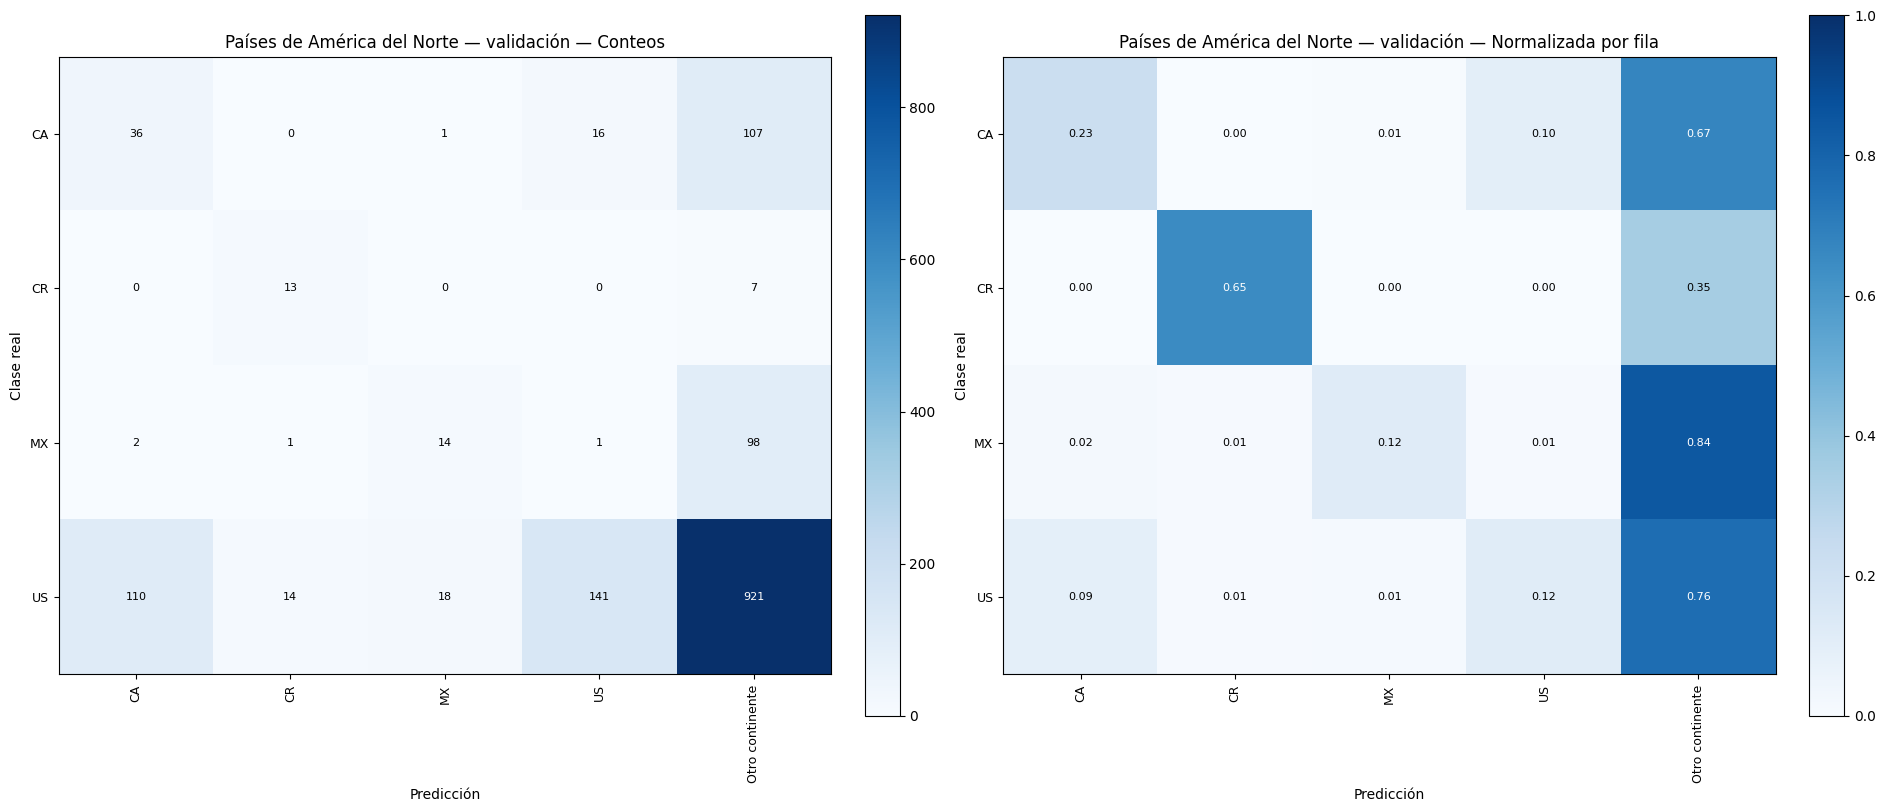

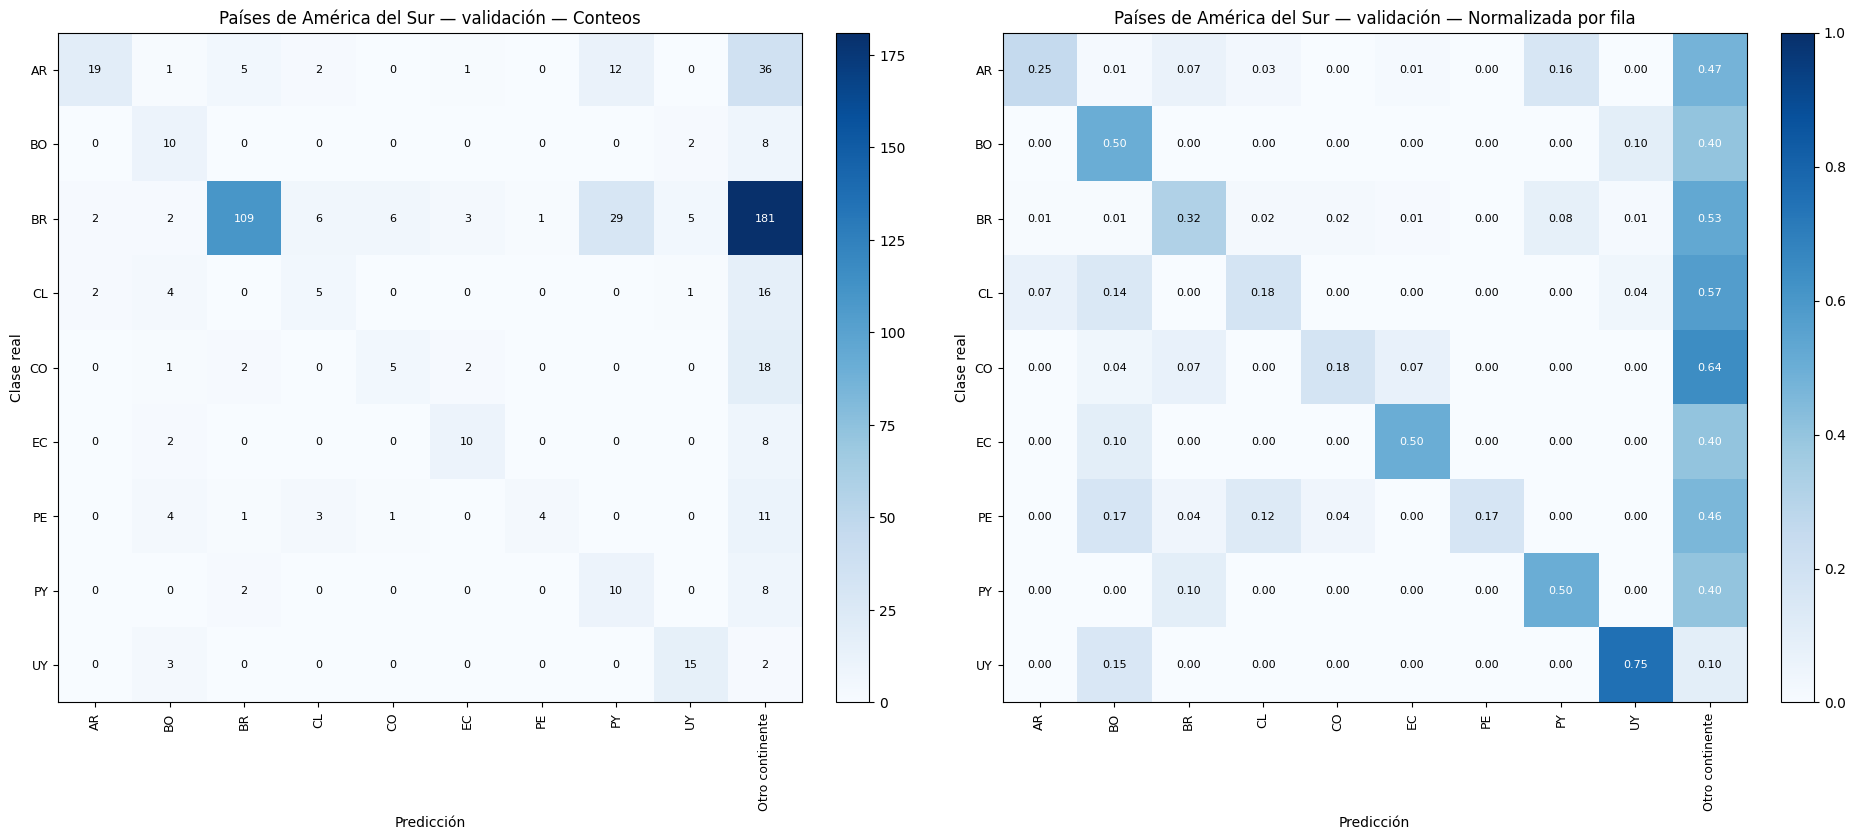

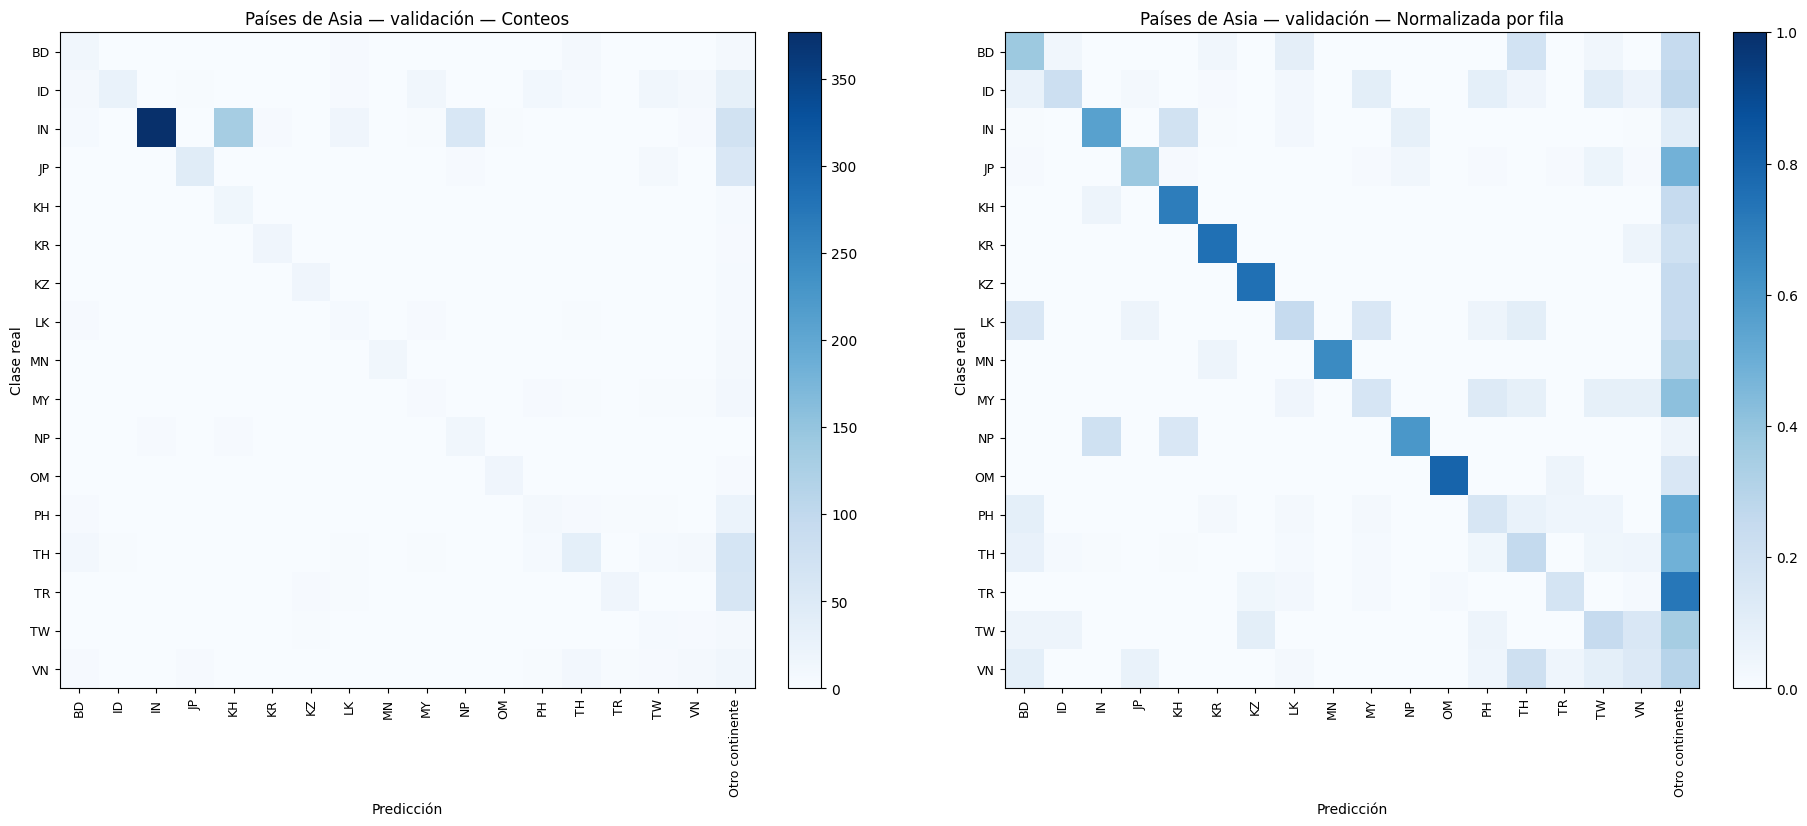

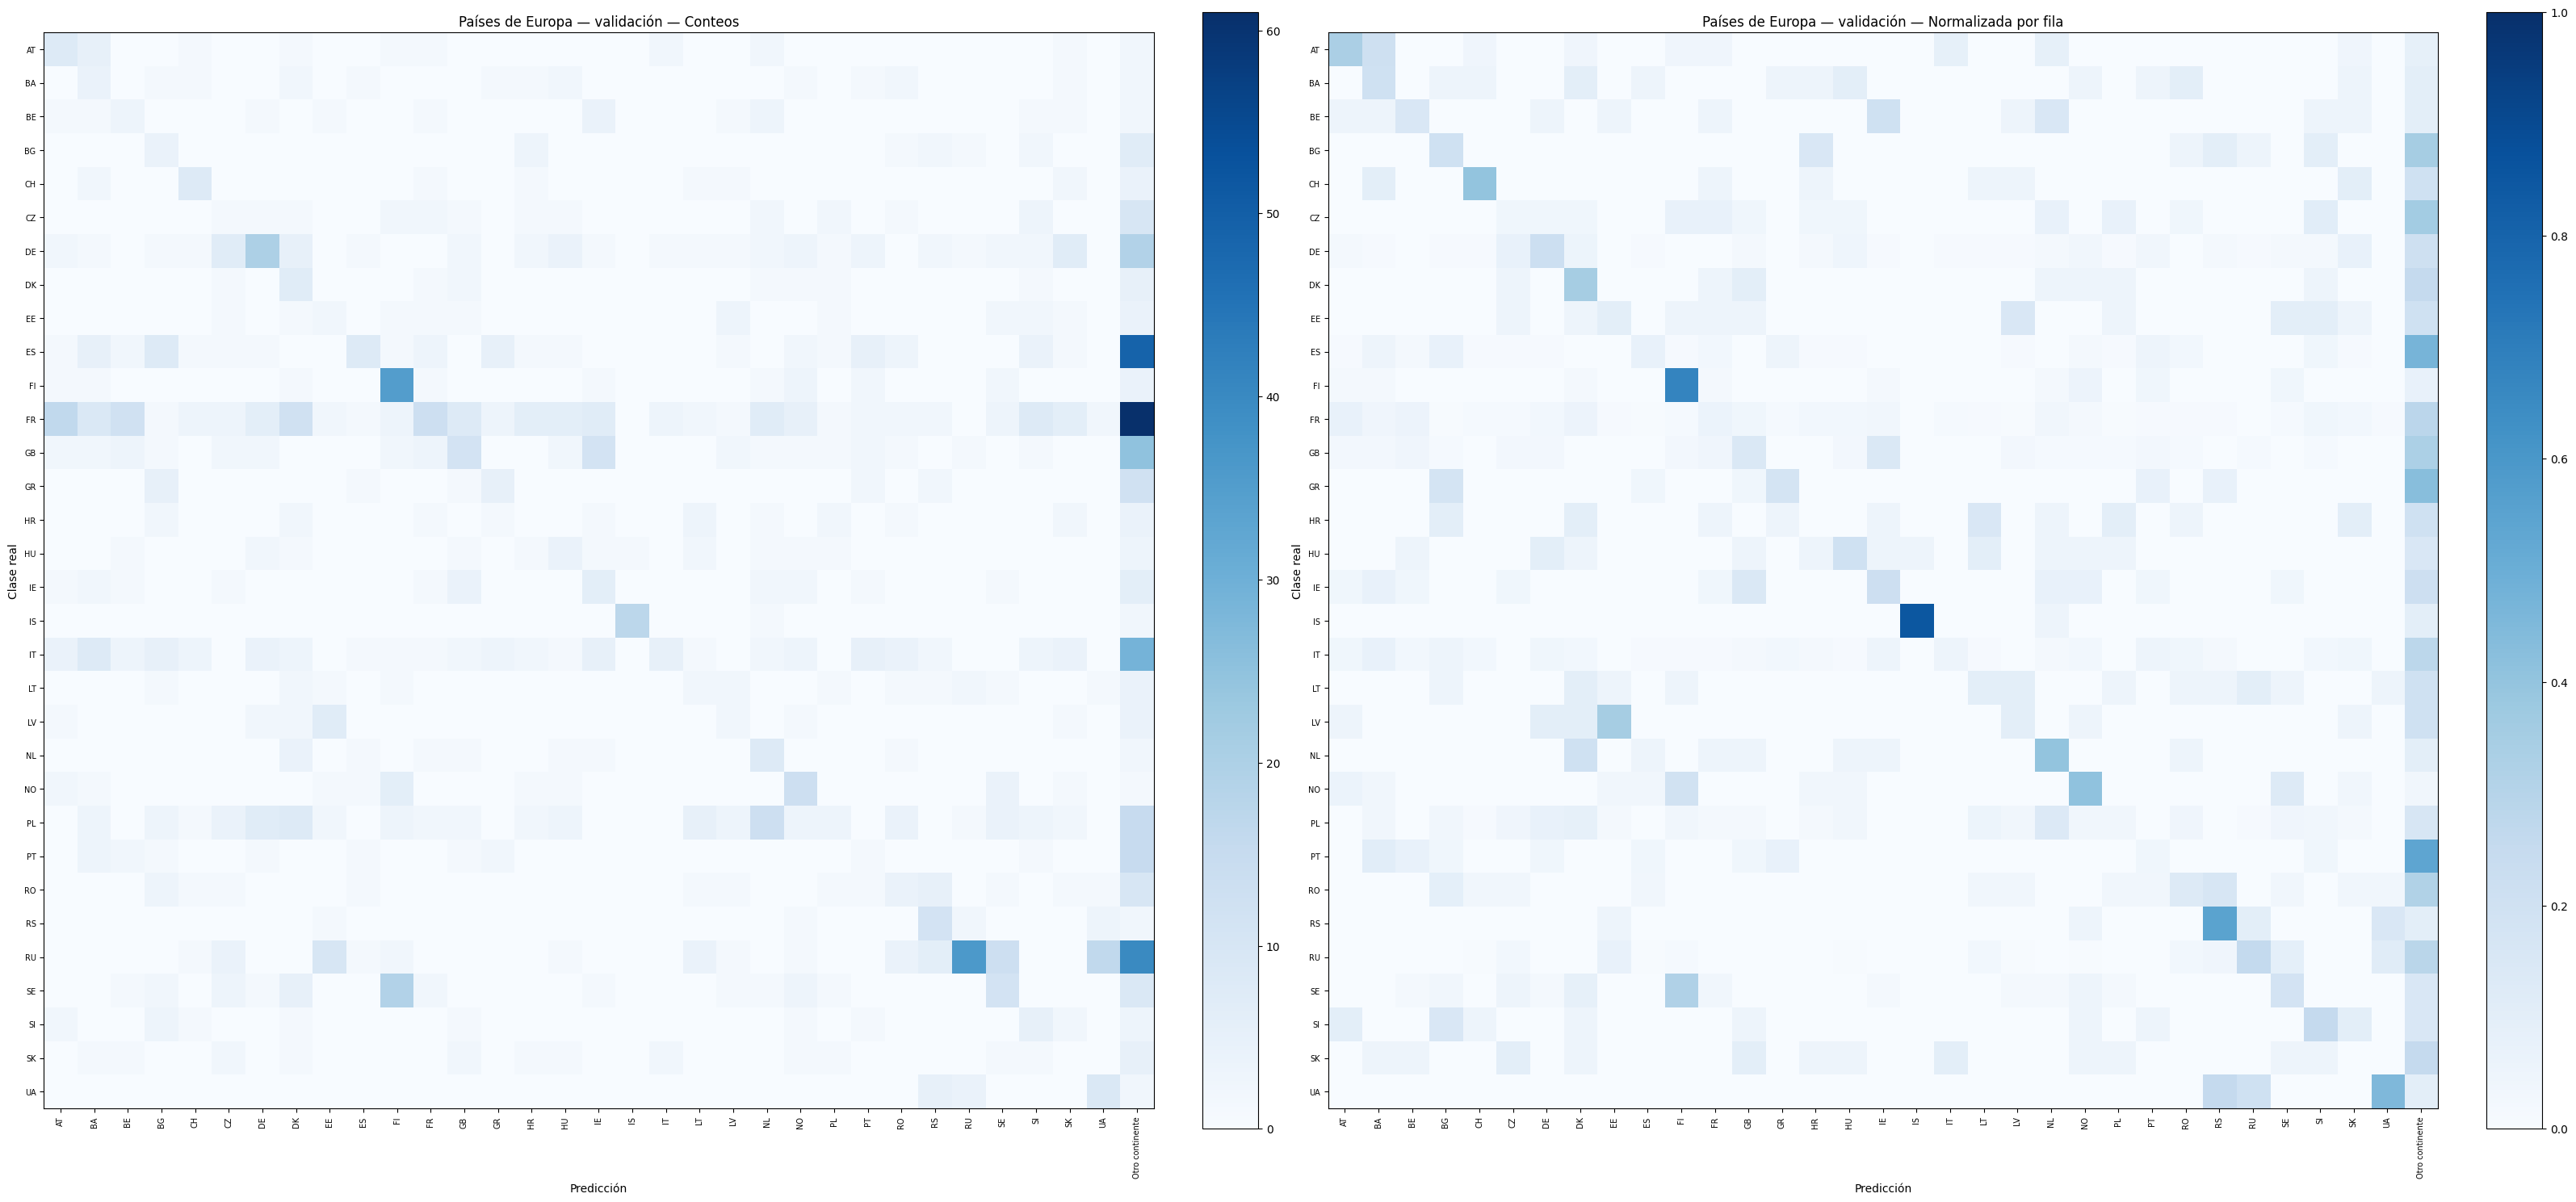

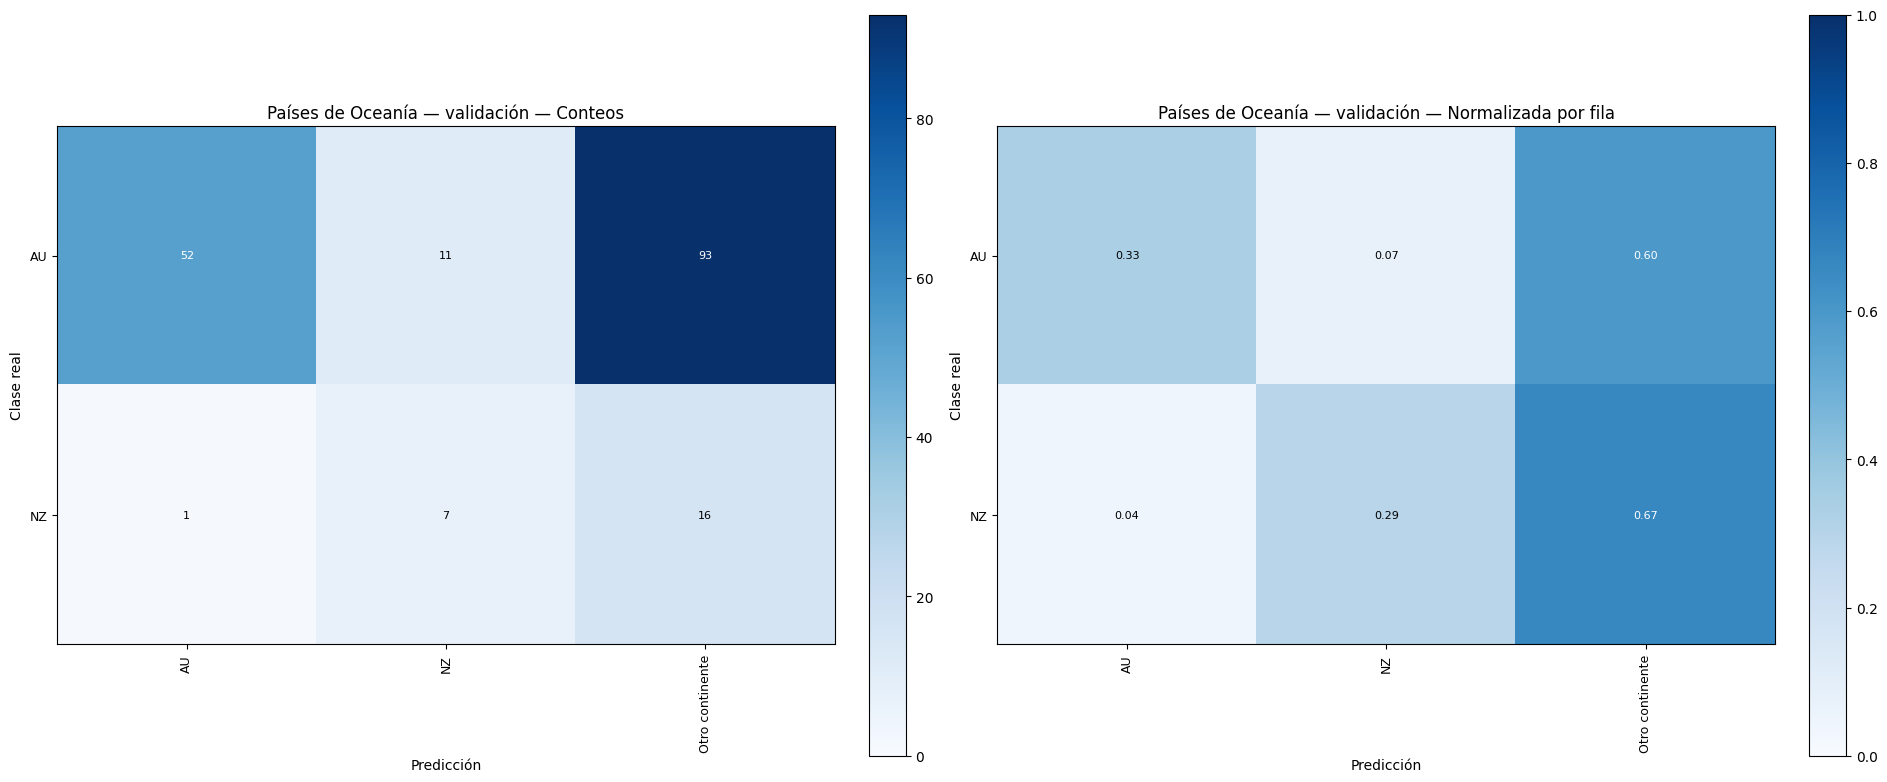

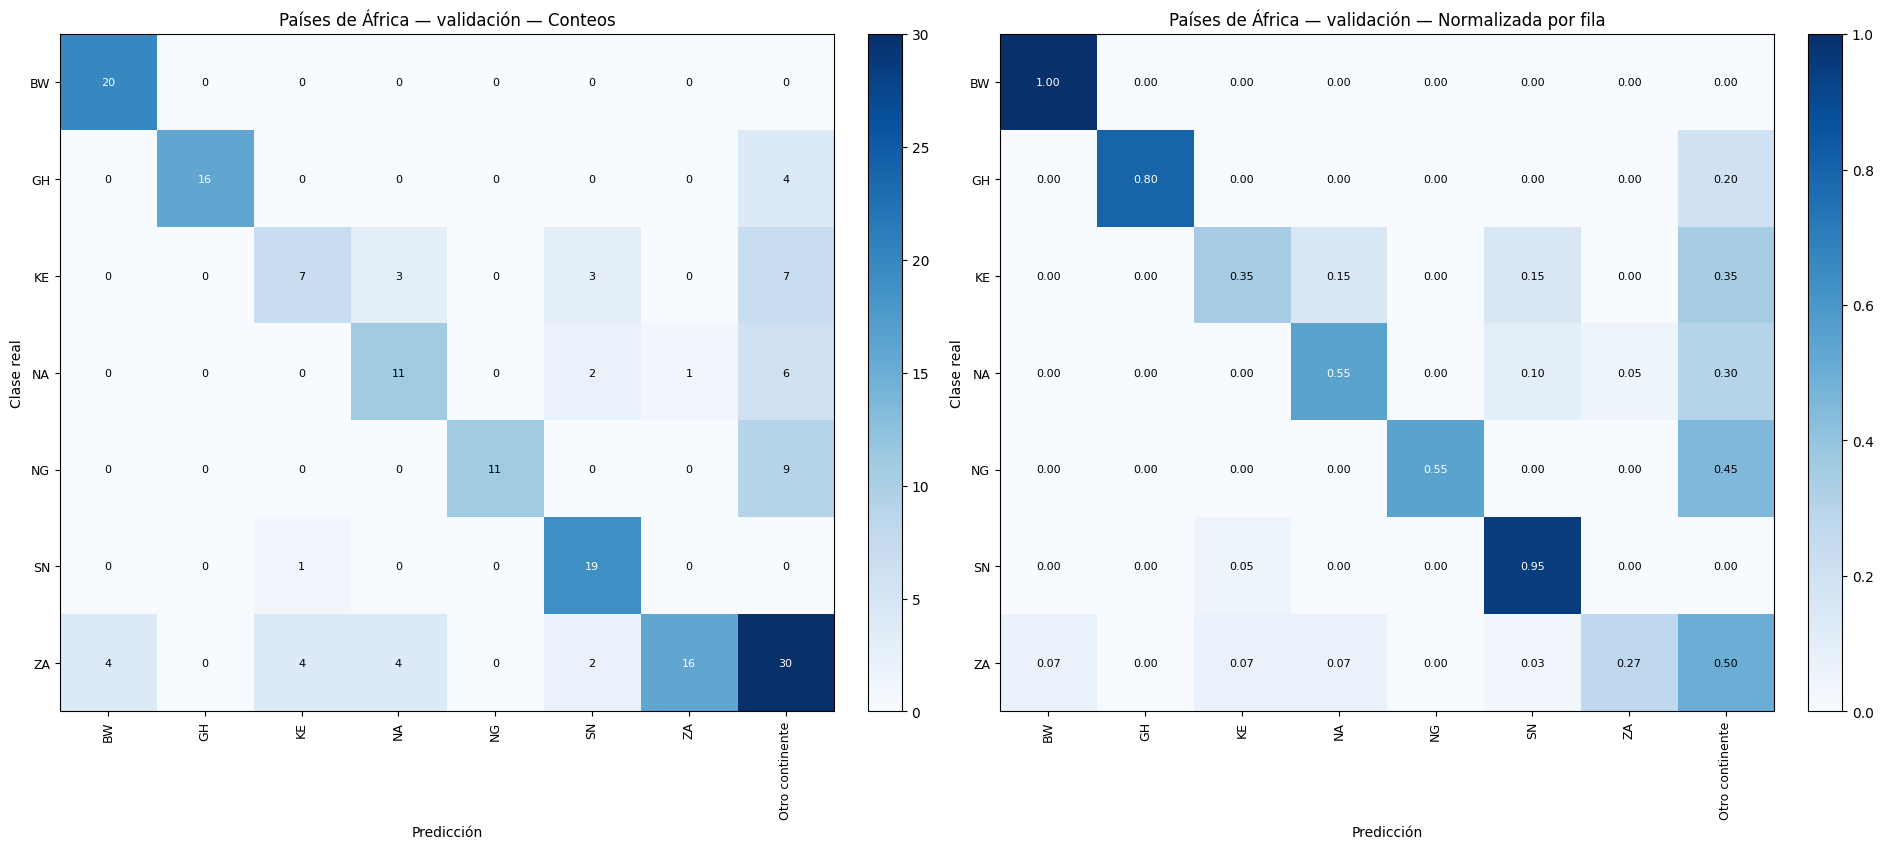

Métricas, predicciones y figuras guardadas en c:\Users\jurad\Documents\facultad\rrnn2\tp-final\geo-project\outputs\resnet18\20261024_115023_590785


In [16]:
for i, continente in enumerate(continentes):
    codigos = [p for p in paises if pais_a_continente[p] == continente]
    subset = predicciones.loc[predicciones["continente_real"] == continente].copy()
    subset["prediccion_agrupada"] = subset["pais_predicho"].where(
        subset["pais_predicho"].isin(codigos), "Otro continente")
    tabla = pd.crosstab(subset["pais_real"], subset["prediccion_agrupada"]).reindex(
        index=codigos, columns=[*codigos, "Otro continente"], fill_value=0)
    assert tabla.to_numpy().sum() == len(subset)
    mostrar_matriz(tabla, f"Países de {continente} — validación",
                   f"confusion_paises_continente_{i + 1}", anotar=len(codigos) <= 12)
print(f"Métricas, predicciones y figuras guardadas en {ruta_resultados}")

# Prueba 2: muestra de 50.000 imágenes

Usamos `datasets/samples/muestra_n-50000_umbral-csv-1000_balanceado_paises-71_seed-42_solo-train`:
**50.000 imágenes de train**, de los mismos 71 países. La validación global de
**3.982 imágenes** se carga desde `datasets/samples/data/validation.parquet`,
igual que en la prueba 1.

Se mantienen el modelo, el optimizador y todos los hiperparámetros de la prueba 1:
ResNet18 desde cero, CrossEntropyLoss, Adam, scheduler, early stopping,
batch efectivo de 32, preprocesamiento, semilla y AMP con CUDA.
Se repiten las curvas de loss, las mismas métricas de accuracy y todas las matrices
de confusión, con los mismos archivos de salida y checkpoints.

Ejecutar las celdas de esta prueba en orden; incluyen sus imports y definiciones,
por lo que también se puede empezar aquí con un kernel nuevo. Se reinicializan
modelo, optimizador, scheduler y estados aleatorios. Los nombres de las variables
se reutilizan; las salidas y archivos de la prueba 1 se conservan.
La corrida nueva se guarda en `outputs/resnet18_50k/<fecha_hora>/`.
Las métricas de ambas pruebas se calculan sobre la misma validación global.


## 1. Configuración y datos

In [17]:
from pathlib import Path
from datetime import datetime
import json
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from datasets import Dataset as HFDataset, Image as HFImage
from PIL import Image
from io import BytesIO
from sklearn.metrics import accuracy_score, confusion_matrix
from tqdm.auto import tqdm
from IPython.display import display

# Rutas absolutas o relativas a la raíz del proyecto.
RUTA_SAMPLE = "datasets/samples/muestra_n-50000_umbral-csv-1000_balanceado_paises-71_seed-42_solo-train"
RUTA_VALIDACION = "datasets/samples/data/validation.parquet"
# Nueva corrida independiente de la prueba 1. Para continuarla, usar su propia carpeta.
REANUDAR = False
RUTA_RESULTADOS = None
EPOCAS = 30  # Total de épocas, incluyendo las ya completadas.
BATCH_SIZE = 4
ACUMULAR_BATCHES = 8  # Batch efectivo: 4 * 8 = 32 imágenes.
LEARNING_RATE = 0.0001
WEIGHT_DECAY = 5e-4
PACIENCIA = 5  # Early stopping según loss de validación.
TAMANO_IMAGEN = 224
NUM_WORKERS = 0  # Compatible con notebooks en Windows.
SEMILLA = 42
USAR_AMP = True  # Precisión mixta solo con CUDA.
DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"

raiz = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "pyproject.toml").is_file()), None)
if raiz is None:
    raise FileNotFoundError("Ejecutá el notebook dentro del proyecto.")
def resolver_ruta(ruta):
    p = Path(ruta).expanduser()
    return (p if p.is_absolute() else raiz / p).resolve()

ruta_sample = resolver_ruta(RUTA_SAMPLE)
if not (ruta_sample / "COMPLETO").is_file():
    raise FileNotFoundError(f"Falta el marcador COMPLETO en {ruta_sample}.")
config_sample = json.loads((ruta_sample / "config.json").read_text(encoding="utf-8"))
archivos = {
    "train": ruta_sample / config_sample["archivos_salida"]["train"],
    "validation": resolver_ruta(RUTA_VALIDACION),
}
for archivo in archivos.values():
    if not archivo.is_file():
        raise FileNotFoundError(archivo)
assert EPOCAS >= 1 and BATCH_SIZE >= 1 and ACUMULAR_BATCHES >= 1
assert PACIENCIA >= 1 and TAMANO_IMAGEN >= 32 and NUM_WORKERS >= 0
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEMILLA)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
device = torch.device(DISPOSITIVO)
amp_activo = USAR_AMP and device.type == "cuda"
ruta_resultados = (resolver_ruta(RUTA_RESULTADOS) if RUTA_RESULTADOS else
                   raiz / "outputs" / "resnet18_50k" / datetime.now().strftime("%Y%m%d_%H%M%S_%f"))
print(f"Sample: {ruta_sample}\nResultados: {ruta_resultados}\nDispositivo: {device}")
if device.type == "cuda":
    print(torch.cuda.get_device_name(device))

FileNotFoundError: Falta el marcador COMPLETO en C:\Users\jurad\Documents\facultad\rrnn2\tp-final\geo-project\datasets\samples\muestra_n-50000_umbral-csv-1000_balanceado_paises-71_seed-42_solo-train.

### Carga y controles de separación

La caché Arrow se guarda en `.cache/modeling/`; las imágenes se decodifican al
solicitarlas, sin cargar todas las imágenes RGB en RAM. Se verifica que no haya
`panoid` compartidos ni países de validación ausentes en entrenamiento.
El vocabulario de clases se construye únicamente con train (incluye `NA`, Namibia).

In [ ]:
datos = {
    split: HFDataset.from_parquet(str(archivo), cache_dir=str(raiz / ".cache/modeling/hf"))
        .cast_column("image", HFImage(decode=False))
    for split, archivo in archivos.items()
}
def metadatos(dataset):
    tabla = dataset.select_columns(["country_code", "panoid", "image_id"]).to_pandas()
    if tabla.isna().any().any():
        raise ValueError("Hay países o identificadores faltantes en el sample.")
    tabla["country_code"] = tabla["country_code"].str.strip().str.upper()
    if (tabla["country_code"] == "").any():
        raise ValueError("Hay códigos de país vacíos.")
    return tabla

meta_train, meta_val = (metadatos(datos[s]) for s in ("train", "validation"))
if not len(meta_train) or not len(meta_val):
    raise ValueError("Ambos splits deben contener imágenes.")
for columna in ("panoid", "image_id"):
    if set(meta_train[columna]) & set(meta_val[columna]):
        raise ValueError(f"Fuga de datos: {columna} compartidos entre splits.")
paises = sorted(meta_train["country_code"].unique().tolist())
pais_a_idx = {pais: i for i, pais in enumerate(paises)}
desconocidos = set(meta_val["country_code"]) - set(paises)
if desconocidos:
    raise ValueError(f"Países de validación sin train: {desconocidos}")
display(pd.DataFrame({
    "train": meta_train["country_code"].value_counts(),
    "validation": meta_val["country_code"].value_counts(),
}).fillna(0).astype(int).sort_index())
print(f"Train: {len(meta_train):,}; validación: {len(meta_val):,}; países: {len(paises)}")

Generating train split: 50000 examples [00:54, 916.85 examples/s] 
Generating train split: 3982 examples [00:05, 680.41 examples/s] 


,train,validation
country_code,,
AR,705,56
AT,705,56
AU,705,56
BA,705,56
BD,705,56
...,...,...
UA,704,56
US,704,56
UY,704,56


Train: 50,000; validación: 3,982; países: 71


### Convención de continentes

Agrupación explícita y editable de seis continentes: América del Norte incluye
Centroamérica y el Caribe. Rusia se asigna a Europa; Turquía y Kazajistán a Asia.
Se verifica la cobertura de todos los países del sample; un país nuevo requiere
agregar su código a esta tabla antes de entrenar.

In [ ]:
GRUPOS_CONTINENTES = {
    "África": "BW GH KE NA NG SN ZA",
    "América del Norte": "CA CR MX US",
    "América del Sur": "AR BO BR CL CO EC PE PY UY",
    "Asia": "BD ID IN JP KH KR KZ LK MN MY NP OM PH TH TR TW VN",
    "Europa": "AT BA BE BG CH CZ DE DK EE ES FI FR GB GR HR HU IE IS IT LT LV NL NO PL PT RO RS RU SE SI SK UA",
    "Oceanía": "AU NZ",
}
pais_a_continente = {pais: continente
                     for continente, codigos in GRUPOS_CONTINENTES.items()
                     for pais in codigos.split()}
sin_continente = set(paises) - set(pais_a_continente)
if sin_continente:
    raise ValueError(f"Completá GRUPOS_CONTINENTES para: {sorted(sin_continente)}")
continentes = sorted({pais_a_continente[p] for p in paises})

In [ ]:
# Escala fija [-1, 1]; no se utilizan pesos ni estadísticas aprendidas de otro dataset.
transform_train = transforms.Compose([
    transforms.Resize(TAMANO_IMAGEN),
    transforms.CenterCrop(TAMANO_IMAGEN),
    transforms.ToTensor(),
    transforms.Normalize((0.5,) * 3, (0.5,) * 3),
])
transform_val = transforms.Compose([
    transforms.Resize(TAMANO_IMAGEN),
    transforms.CenterCrop(TAMANO_IMAGEN),
    transforms.ToTensor(),
    transforms.Normalize((0.5,) * 3, (0.5,) * 3),
])

class ImagenesPaises(Dataset):
    def __init__(self, datos, etiquetas, transform):
        self.datos = datos
        self.etiquetas = etiquetas["country_code"].map(pais_a_idx).to_numpy(dtype=np.int64)
        self.transform = transform

    def __len__(self):
        return len(self.datos)

    def __getitem__(self, idx):
        contenido = self.datos[int(idx)]["image"]
        if contenido.get("bytes") is not None:
            fuente = BytesIO(contenido["bytes"])
        else:
            fuente = resolver_ruta(contenido["path"])
        with Image.open(fuente) as imagen:
            tensor = self.transform(imagen.convert("RGB"))
        return tensor, int(self.etiquetas[idx])

dataset_train = ImagenesPaises(datos["train"], meta_train, transform_train)
dataset_val = ImagenesPaises(datos["validation"], meta_val, transform_val)
loader_train = DataLoader(dataset_train, batch_size=BATCH_SIZE, shuffle=True,
                          generator=torch.Generator().manual_seed(SEMILLA),
                          num_workers=NUM_WORKERS, pin_memory=device.type == "cuda")
loader_val = DataLoader(dataset_val, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=device.type == "cuda")

## 2. Fase de entrenamiento

ResNet18 con inicialización aleatoria y todas las capas entrenables.
Optimizador Adam, reducción de learning rate y early stopping según loss de
validación. Train y validación usan el mismo preprocesamiento determinista,
sin aumentación. La loss de train se mide en modo entrenamiento y la de
validación en modo evaluación; BatchNorm utiliza estadísticas del batch en train
y las estadísticas acumuladas en validación. Ambas losses son promedios por imagen.

Se guarda el modelo de **menor loss de validación**, el historial y la configuración.
Cada ejecución usa su propia carpeta. Si hay falta de memoria, reducir `BATCH_SIZE`
y aumentar `ACUMULAR_BATCHES` para conservar el batch efectivo.

### Continuar después de reiniciar el kernel

La configuración de esta prueba empieza una corrida nueva. Si se interrumpe,
indicar su carpeta `outputs/resnet18_50k/<fecha_hora>/` en `RUTA_RESULTADOS` y
cambiar a `REANUDAR=True`. Ejecutar las secciones 1 y 2 de esta prueba en orden:
se reconstruyen datos y modelo antes de cargar el checkpoint. `EPOCAS` es el
total objetivo (30), incluyendo las épocas ya completadas.

- `ultimo_entrenamiento.pt`: estado al terminar la última época completa, con
  modelo, Adam, scheduler, GradScaler, historial, early stopping y estados aleatorios
  de Python, NumPy, PyTorch, CUDA y el generador del DataLoader.
- `mejor_resnet18.pt`: pesos del modelo de menor loss de validación, para métricas.

Se prefiere el último checkpoint completo. Si solo existe el checkpoint antiguo de
pesos, se recuperan sus pesos y el historial hasta esa época; **Adam y el scheduler
comienzan nuevos**. Una corrida nueva de esta prueba guarda el estado completo
desde la primera época.

Los guardados se reemplazan de forma atómica: una escritura interrumpida no pisa
el checkpoint anterior. Se recupera desde el **final de una época**, no desde un
batch intermedio. Para reproducir la secuencia se debe conservar la configuración,
el entorno y el dispositivo; se controla su compatibilidad antes de cargar estados.
Con `NUM_WORKERS=0` se conserva también la secuencia de carga y transformaciones.
Para una corrida nueva, usar `REANUDAR=False` y `RUTA_RESULTADOS=None`.


In [ ]:
# Liberar el modelo y el optimizador anteriores antes de reservar memoria para esta prueba.
import gc
for nombre in ("modelo", "optimizador", "scheduler", "scaler"):
    globals().pop(nombre, None)
gc.collect()
if device.type == "cuda":
    torch.cuda.empty_cache()

modelo = models.resnet18(weights=None, num_classes=len(paises)).to(device)
criterio = nn.CrossEntropyLoss()
optimizador = torch.optim.Adam(modelo.parameters(), lr=LEARNING_RATE,
                               weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizador, factor=0.1, patience=2)
scaler = torch.amp.GradScaler("cuda", enabled=amp_activo)
print(f"Parámetros entrenables: {sum(p.numel() for p in modelo.parameters() if p.requires_grad):,}")

def ejecutar_epoca(modelo, loader, entrenar):
    modelo.train(entrenar)
    total_loss, total = 0.0, 0
    if entrenar:
        optimizador.zero_grad(set_to_none=True)
    with torch.set_grad_enabled(entrenar):
        for paso, (imagenes, etiquetas) in enumerate(tqdm(loader, desc="Train" if entrenar else "Validación")):
            imagenes = imagenes.to(device, non_blocking=True)
            etiquetas = etiquetas.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, enabled=amp_activo):
                logits = modelo(imagenes)
                loss = criterio(logits, etiquetas)
            n = etiquetas.size(0)
            if entrenar:
                # Ponderar por imágenes, incluso en el último grupo incompleto.
                inicio_grupo = (paso // ACUMULAR_BATCHES) * ACUMULAR_BATCHES
                n_grupo = min(ACUMULAR_BATCHES * loader.batch_size,
                              len(loader.dataset) - inicio_grupo * loader.batch_size)
                scaler.scale(loss * n / n_grupo).backward()
                if (paso + 1) % ACUMULAR_BATCHES == 0 or paso + 1 == len(loader):
                    scaler.step(optimizador)
                    scaler.update()
                    optimizador.zero_grad(set_to_none=True)
            total_loss += loss.detach().item() * n
            total += n
    return total_loss / total

Parámetros entrenables: 11,212,935


In [ ]:
def guardar_checkpoint(estado, destino):
    """No reemplazar un archivo válido hasta completar la escritura."""
    temporal = destino.with_name(destino.name + ".tmp")
    torch.save(estado, temporal)
    temporal.replace(destino)


def capturar_azar():
    estado_np = np.random.get_state()
    return {
        "python": random.getstate(),
        "numpy": {"generador": estado_np[0], "claves": estado_np[1].tolist(),
                  "posicion": int(estado_np[2]), "gauss": int(estado_np[3]),
                  "cache_gauss": float(estado_np[4])},
        "torch_cpu": torch.get_rng_state(),
        "torch_cuda": torch.cuda.get_rng_state_all() if device.type == "cuda" else [],
        "loader_train": loader_train.generator.get_state(),
    }


def restaurar_azar(estado):
    random.setstate(estado["python"])
    s = estado["numpy"]
    np.random.set_state((s["generador"], np.asarray(s["claves"], dtype=np.uint32),
                         s["posicion"], s["gauss"], s["cache_gauss"]))
    torch.set_rng_state(estado["torch_cpu"])
    if device.type == "cuda":
        if len(estado["torch_cuda"]) != torch.cuda.device_count():
            raise ValueError("Cambió la cantidad de GPUs; no se puede restaurar el estado CUDA.")
        torch.cuda.set_rng_state_all(estado["torch_cuda"])
    loader_train.generator.set_state(estado["loader_train"])


def validar_config_reanudacion(guardada, actual, completa):
    claves = ["arquitectura", "paises", "pais_a_continente", "tamano_imagen",
              "batch_size", "acumular_batches", "learning_rate", "optimizador",
              "weight_decay", "paciencia", "semilla", "filas_train", "filas_validation"]
    if completa:
        claves += ["amp", "torch", "dispositivo", "num_workers", "archivos_sample",
                   "preprocesamiento_train", "preprocesamiento_val"]
    diferencias = [k for k in claves if guardada.get(k) != actual.get(k)]
    if Path(guardada["ruta_sample"]).resolve() != Path(actual["ruta_sample"]).resolve():
        diferencias.append("ruta_sample")
    if diferencias:
        raise ValueError(f"Configuración distinta a la del checkpoint: {diferencias}")


def guardar_historial(historial):
    destino = ruta_resultados / "historial.csv"
    temporal = destino.with_name(destino.name + ".tmp")
    pd.DataFrame(historial).to_csv(temporal, index=False)
    temporal.replace(destino)

In [ ]:
ruta_checkpoint = ruta_resultados / "mejor_resnet18.pt"
ruta_ultimo = ruta_resultados / "ultimo_entrenamiento.pt"
config_entrenamiento = {
    "arquitectura": "resnet18", "weights": None, "ruta_sample": str(ruta_sample),
    "epocas_maximas": EPOCAS, "batch_size": BATCH_SIZE, "acumular_batches": ACUMULAR_BATCHES,
    "learning_rate": LEARNING_RATE, "optimizador": "Adam", "weight_decay": WEIGHT_DECAY,
    "paciencia": PACIENCIA, "tamano_imagen": TAMANO_IMAGEN, "semilla": SEMILLA,
    "amp": amp_activo, "paises": paises, "pais_a_continente": pais_a_continente,
    "filas_train": len(dataset_train), "filas_validation": len(dataset_val),
    "torch": str(torch.__version__), "dispositivo": str(device), "num_workers": NUM_WORKERS,
    "preprocesamiento_train": repr(transform_train), "preprocesamiento_val": repr(transform_val),
    "archivos_sample": {s: {"bytes": p.stat().st_size, "mtime_ns": p.stat().st_mtime_ns}
                        for s, p in archivos.items()},
}
historial = []
mejor_loss, sin_mejora, epoca_inicio = float("inf"), 0, 1

if REANUDAR:
    origen = ruta_ultimo if ruta_ultimo.is_file() else ruta_checkpoint
    if not origen.is_file():
        raise FileNotFoundError(f"No hay checkpoint para continuar en {ruta_resultados}")
    estado = torch.load(origen, map_location="cpu", weights_only=True)
    completa = "optimizer_state_dict" in estado
    validar_config_reanudacion(estado["config"], config_entrenamiento, completa)
    modelo.load_state_dict(estado["model_state_dict"])
    epoca_guardada = int(estado["epoca"])
    epoca_inicio = epoca_guardada + 1
    if completa:
        optimizador.load_state_dict(estado["optimizer_state_dict"])
        scheduler.load_state_dict(estado["scheduler_state_dict"])
        scaler.load_state_dict(estado["scaler_state_dict"])
        historial = estado["historial"]
        mejor_loss = float(estado["mejor_loss"])
        sin_mejora = int(estado["sin_mejora"])
        restaurar_azar(estado["azar"])
        print(f"Estado completo recuperado de época {epoca_guardada}.")
    else:
        # El formato anterior solo conservaba pesos, época, loss y configuración.
        historial_previo = pd.read_csv(ruta_resultados / "historial.csv")
        historial = historial_previo.loc[historial_previo["epoca"] <= epoca_guardada].to_dict("records")
        if [int(f["epoca"]) for f in historial] != list(range(1, epoca_guardada + 1)):
            raise ValueError("El historial antiguo no contiene todas las épocas del checkpoint.")
        if not np.isclose(historial[-1]["loss_validation"], estado["loss_validation"]):
            raise ValueError("La loss del checkpoint no coincide con su fila del historial.")
        mejor_loss = float(estado["loss_validation"])
        print(f"Pesos recuperados de época {epoca_guardada}. Adam, scheduler y GradScaler nuevos.")
        if len(historial_previo) > len(historial):
            print("Las épocas posteriores al checkpoint no se retoman; no se conservaron sus pesos.")
    if len(historial) != epoca_guardada or int(historial[-1]["epoca"]) != epoca_guardada:
        raise ValueError("El historial no coincide con la época del checkpoint.")
    del estado
    print(f"Próxima época: {epoca_inicio}; total objetivo: {EPOCAS}.")
else:
    if any((ruta_resultados / nombre).exists() for nombre in
           ("mejor_resnet18.pt", "ultimo_entrenamiento.pt", "historial.csv", "config_entrenamiento.json")):
        raise FileExistsError("La carpeta ya contiene una corrida. Usá REANUDAR=True u otra carpeta.")
    ruta_resultados.mkdir(parents=True, exist_ok=True)
    (ruta_resultados / "config_entrenamiento.json").write_text(
        json.dumps(config_entrenamiento, ensure_ascii=False, indent=2), encoding="utf-8")

In [ ]:
if epoca_inicio > EPOCAS:
    print(f"Ya se completaron {epoca_inicio - 1} épocas; no hay épocas nuevas para ejecutar.")
for epoca in range(epoca_inicio, EPOCAS + 1):
    if sin_mejora >= PACIENCIA:
        print(f"Early stopping ya alcanzado: {PACIENCIA} épocas sin mejora.")
        break
    inicio = time.perf_counter()
    lr = optimizador.param_groups[0]["lr"]
    loss_train = ejecutar_epoca(modelo, loader_train, entrenar=True)
    loss_val = ejecutar_epoca(modelo, loader_val, entrenar=False)
    if not np.isfinite([loss_train, loss_val]).all():
        raise RuntimeError("Loss no finita. El checkpoint anterior sigue disponible.")
    historial.append({"epoca": epoca, "loss_train": loss_train, "loss_validation": loss_val,
                      "learning_rate": lr, "segundos": time.perf_counter() - inicio})
    if loss_val < mejor_loss:
        mejor_loss, sin_mejora = loss_val, 0
        guardar_checkpoint({"model_state_dict": modelo.state_dict(), "epoca": epoca,
                            "loss_validation": loss_val, "config": config_entrenamiento}, ruta_checkpoint)
    else:
        sin_mejora += 1
    scheduler.step(loss_val)
    # Checkpoint completo después del scheduler y antes de comenzar otra época.
    guardar_checkpoint({
        "version": 1, "model_state_dict": modelo.state_dict(), "epoca": epoca,
        "loss_validation": loss_val, "config": config_entrenamiento,
        "optimizer_state_dict": optimizador.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(), "scaler_state_dict": scaler.state_dict(),
        "mejor_loss": mejor_loss, "sin_mejora": sin_mejora,
        "historial": historial, "azar": capturar_azar(),
    }, ruta_ultimo)
    # El historial del checkpoint es la fuente de recuperación si se interrumpe el CSV.
    guardar_historial(historial)
    print(f"Época {epoca}/{EPOCAS} | train={loss_train:.4f} | val={loss_val:.4f} | lr={lr:.5g}")
    if sin_mejora >= PACIENCIA:
        print(f"Early stopping: {PACIENCIA} épocas sin mejora.")
        break
print(f"Mejor loss de validación: {mejor_loss:.4f}; checkpoint: {ruta_checkpoint}")

Validación: 100%|██████████| 996/996 [00:47<00:00, 20.81it/s]


Época 1/30 | train=3.6166 | val=3.2480 | lr=0.0001


Validación: 100%|██████████| 996/996 [00:47<00:00, 21.00it/s]


Época 2/30 | train=3.1770 | val=2.9299 | lr=0.0001


Validación: 100%|██████████| 996/996 [00:47<00:00, 20.95it/s]


...

Época 14/30 | train=1.2813 | val=2.5223 | lr=0.0001


Validación: 100%|██████████| 996/996 [00:47<00:00, 21.08it/s]


Época 15/30 | train=0.7707 | val=2.3037 | lr=1e-05


Validación: 100%|██████████| 996/996 [00:47<00:00, 21.17it/s]


Época 16/30 | train=0.6208 | val=2.3510 | lr=1e-05
Early stopping: 5 épocas sin mejora.
Mejor loss de validación: 2.2741; checkpoint: c:\Users\jurad\Documents\facultad\rrnn2\tp-final\geo-project\outputs\resnet18_50k\20261019_112821_798407\mejor_resnet18.pt


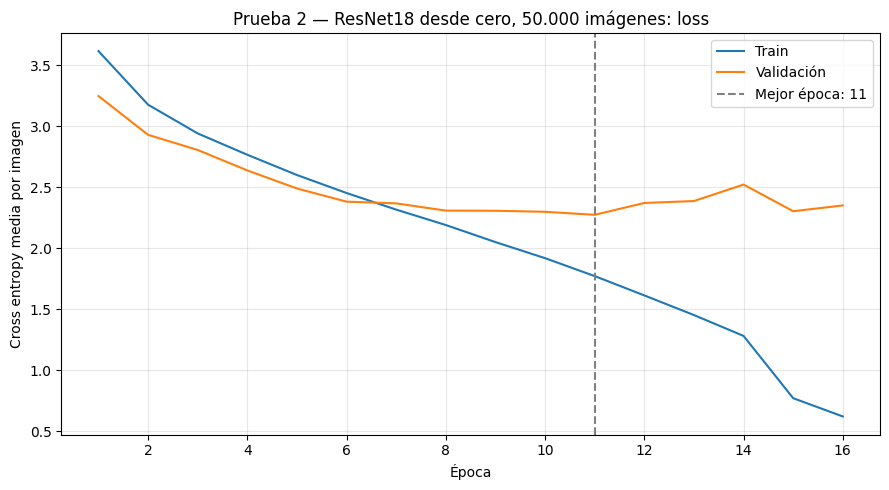

In [ ]:
historia = (pd.DataFrame(historial) if "historial" in globals() and historial
            else pd.read_csv(ruta_resultados / "historial.csv"))
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(historia["epoca"], historia["loss_train"], label="Train")
ax.plot(historia["epoca"], historia["loss_validation"], label="Validación")
mejor_epoca = int(historia.loc[historia["loss_validation"].idxmin(), "epoca"])
ax.axvline(mejor_epoca, color="gray", linestyle="--", label=f"Mejor época: {mejor_epoca}")
ax.set(xlabel="Época", ylabel="Cross entropy media por imagen", title="Prueba 2 — ResNet18 desde cero, 50.000 imágenes: loss")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(ruta_resultados / "curvas_loss.png", dpi=160)
plt.show()

## 3. Métricas sobre validación

Esta fase carga el mejor checkpoint y evalúa **todo el conjunto de validación**,
sin gradientes y con BatchNorm en modo evaluación. Para repetirla sin entrenar, indicar
`RUTA_RESULTADOS` de una ejecución previa, ejecutar la sección 1 y luego esta sección.
El tamaño de imagen y el sample deben coincidir con los del checkpoint.

Reportamos accuracy de país global, accuracy de país por continente real y
accuracy de continente (se toma el continente del país predicho por argmax).
Las matrices incluyen país × país, continente × continente y una matriz de países
por cada continente. Como validación también selecciona el checkpoint, estos
resultados no son una estimación final sobre un conjunto de test independiente.

In [ ]:
ruta_checkpoint = ruta_resultados / "mejor_resnet18.pt"
checkpoint = torch.load(ruta_checkpoint, map_location="cpu", weights_only=True)
config_guardada = checkpoint["config"]
if config_guardada["arquitectura"] != "resnet18":
    raise ValueError("El checkpoint no corresponde a ResNet18.")
if (config_guardada["paises"] != paises
        or Path(config_guardada["ruta_sample"]).resolve() != ruta_sample
        or config_guardada["tamano_imagen"] != TAMANO_IMAGEN
        or config_guardada["pais_a_continente"] != pais_a_continente):
    raise ValueError("Sample, clases, continentes o tamaño de imagen distintos del entrenamiento.")
# Liberar estados del optimizador si se acaba de entrenar, antes de evaluar.
if "optimizador" in globals():
    optimizador.state.clear()
if "modelo" not in globals():
    modelo = models.resnet18(weights=None, num_classes=len(paises)).to(device)
modelo.load_state_dict(checkpoint["model_state_dict"])
print(f"Evaluando checkpoint de época {checkpoint['epoca']} (loss={checkpoint['loss_validation']:.4f})")
del checkpoint
modelo.eval()
reales, predichos = [], []
with torch.inference_mode():
    for imagenes, etiquetas in tqdm(loader_val, desc="Métricas de validación"):
        with torch.autocast(device_type=device.type, enabled=amp_activo):
            logits = modelo(imagenes.to(device, non_blocking=True))
        reales.extend(etiquetas.numpy().tolist())
        predichos.extend(logits.argmax(dim=1).cpu().tolist())
y_true, y_pred = np.asarray(reales), np.asarray(predichos)
assert len(y_true) == len(dataset_val) == len(meta_val)
predicciones = meta_val[["image_id", "panoid", "country_code"]].copy()
predicciones = predicciones.rename(columns={"country_code": "pais_real"})
predicciones["pais_predicho"] = np.asarray(paises)[y_pred]
predicciones["continente_real"] = predicciones["pais_real"].map(pais_a_continente)
predicciones["continente_predicho"] = predicciones["pais_predicho"].map(pais_a_continente)
predicciones["acierto_pais"] = y_true == y_pred
predicciones["acierto_continente"] = (predicciones["continente_real"] == predicciones["continente_predicho"])
predicciones.to_csv(ruta_resultados / "predicciones_validation.csv", index=False)
accuracy_pais = accuracy_score(y_true, y_pred)
accuracy_continente = accuracy_score(predicciones["continente_real"], predicciones["continente_predicho"])
resumen_metricas = {"n_validation": len(y_true), "accuracy_pais": accuracy_pais,
                    "accuracy_continente": accuracy_continente}
print(f"Accuracy de país: {accuracy_pais:.2%}")
print(f"Accuracy de continente: {accuracy_continente:.2%}")
por_continente = predicciones.groupby("continente_real").agg(
    n=("acierto_pais", "size"), accuracy_pais=("acierto_pais", "mean"),
    accuracy_continente=("acierto_continente", "mean"))
display(por_continente.style.format({"accuracy_pais": "{:.2%}", "accuracy_continente": "{:.2%}"}))
por_continente.to_csv(ruta_resultados / "accuracy_por_continente.csv")
(ruta_resultados / "metricas_validation.json").write_text(
    json.dumps(resumen_metricas, ensure_ascii=False, indent=2), encoding="utf-8")

Evaluando checkpoint de época 11 (loss=2.2741)


Métricas de validación: 100%|██████████| 996/996 [00:46<00:00, 21.30it/s]


Accuracy de país: 40.68%
Accuracy de continente: 72.65%


,n,accuracy_pais,accuracy_continente
continente_real,,,
América del Norte,225,27.11%,31.11%
América del Sur,504,44.64%,57.94%
Asia,953,49.42%,75.45%
Europa,1793,29.11%,80.31%
Oceanía,112,54.46%,65.18%
África,395,70.89%,75.70%


111

### Matrices de confusión globales

Filas = clase real; columnas = clase predicha. Se muestran conteos y proporciones
normalizadas por fila (recall de cada clase en la diagonal). Los CSV conservan los
conteos y las figuras se guardan en la carpeta de resultados.

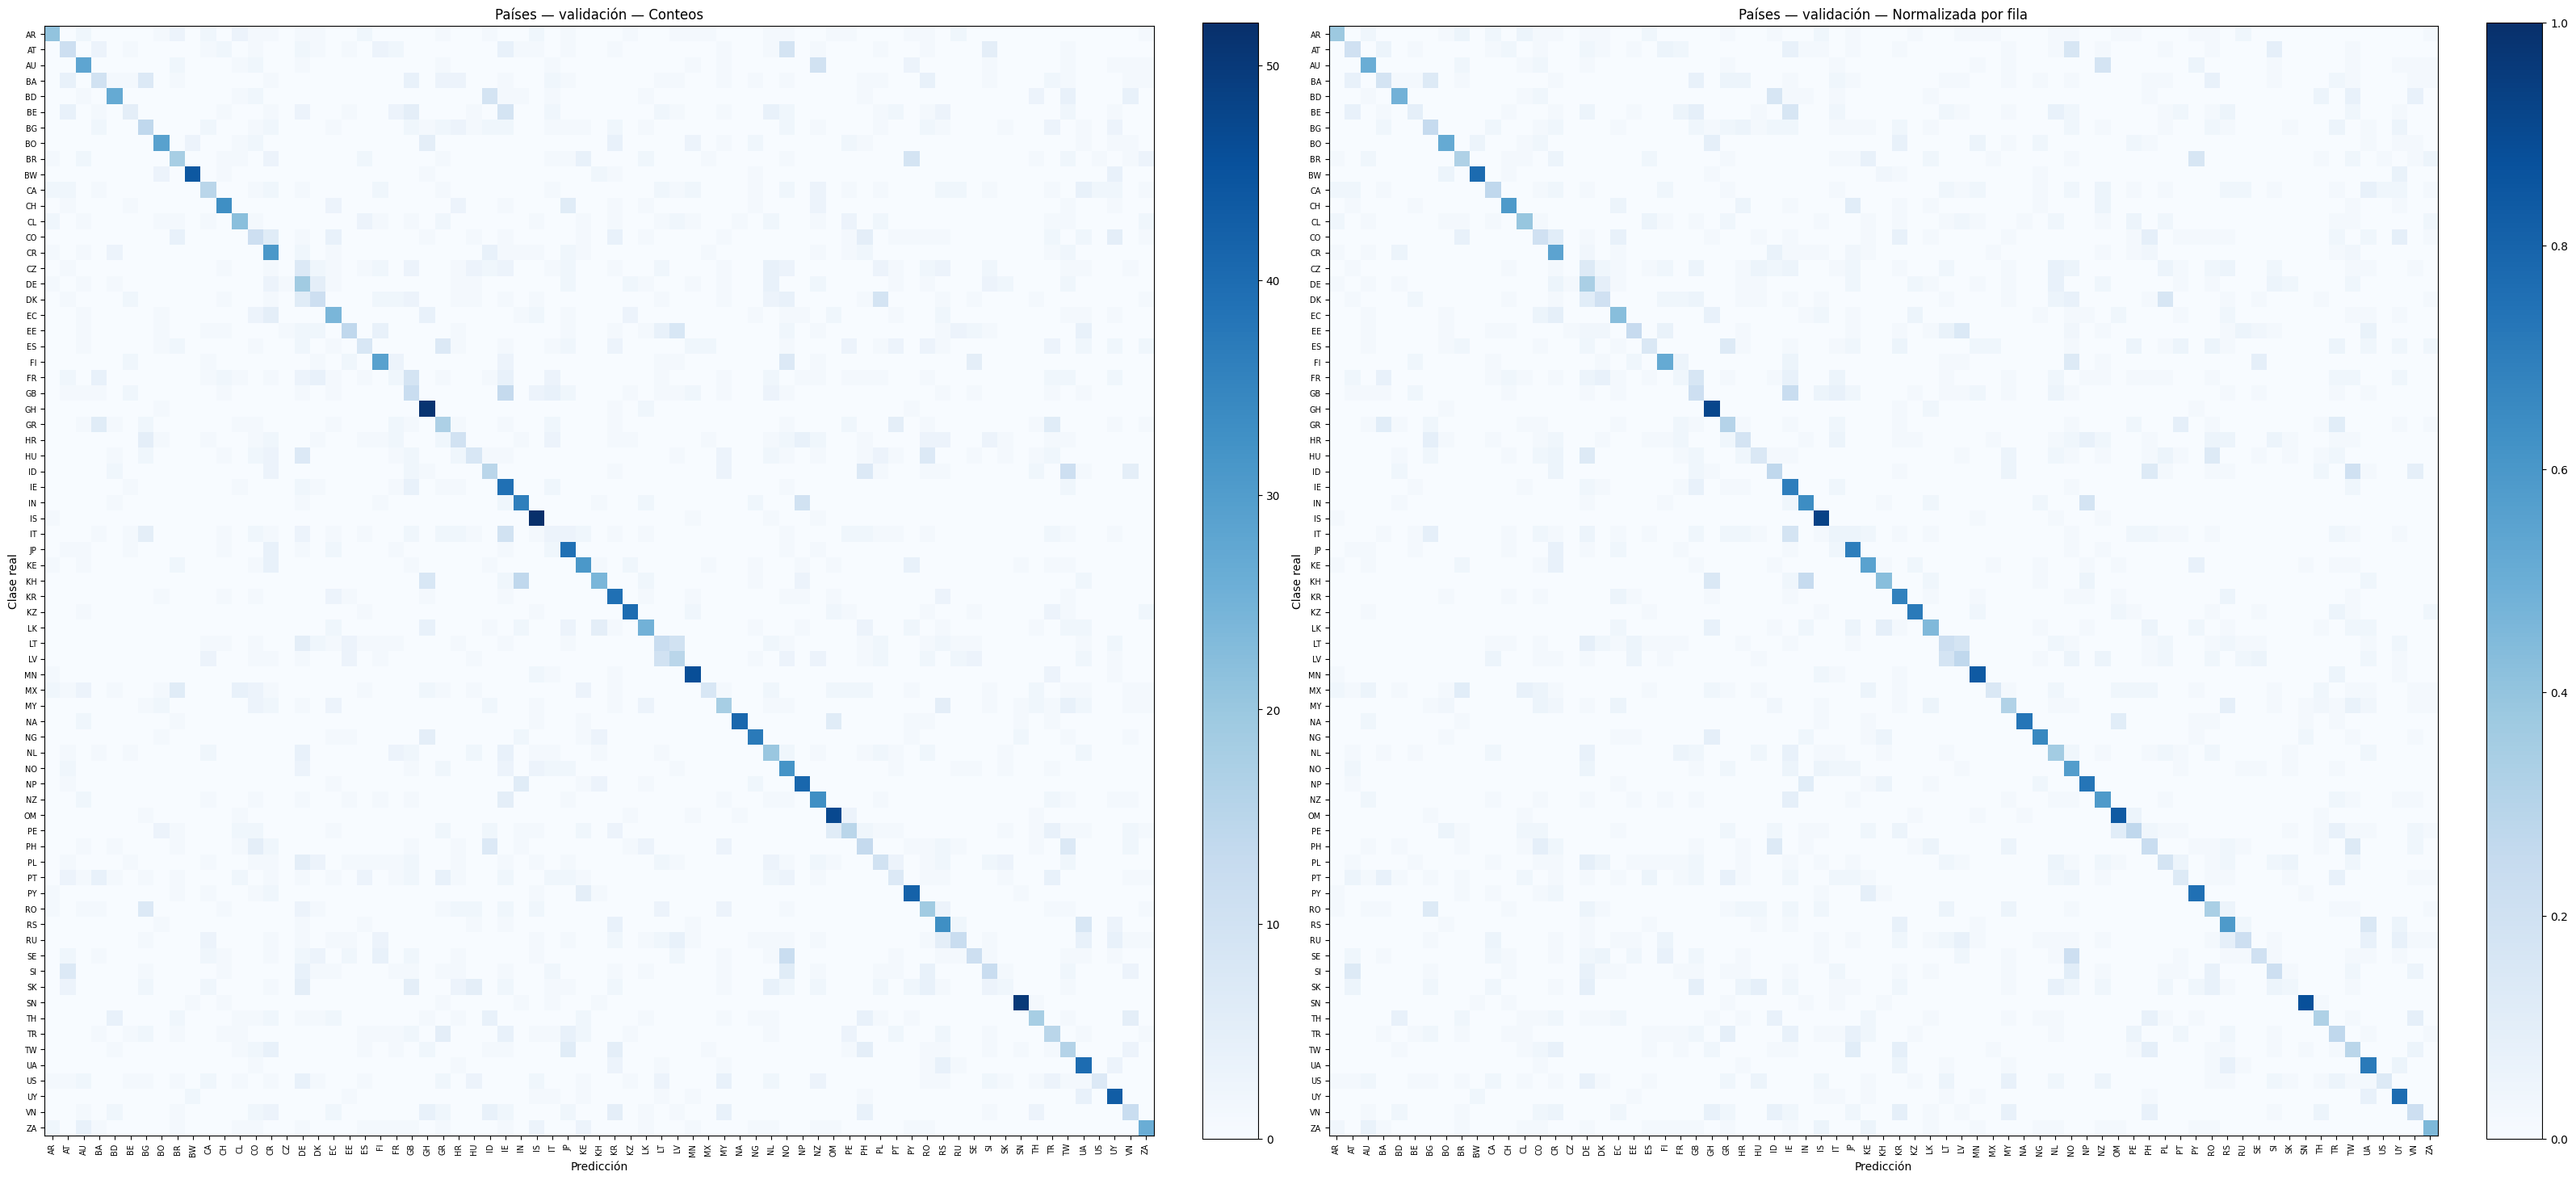

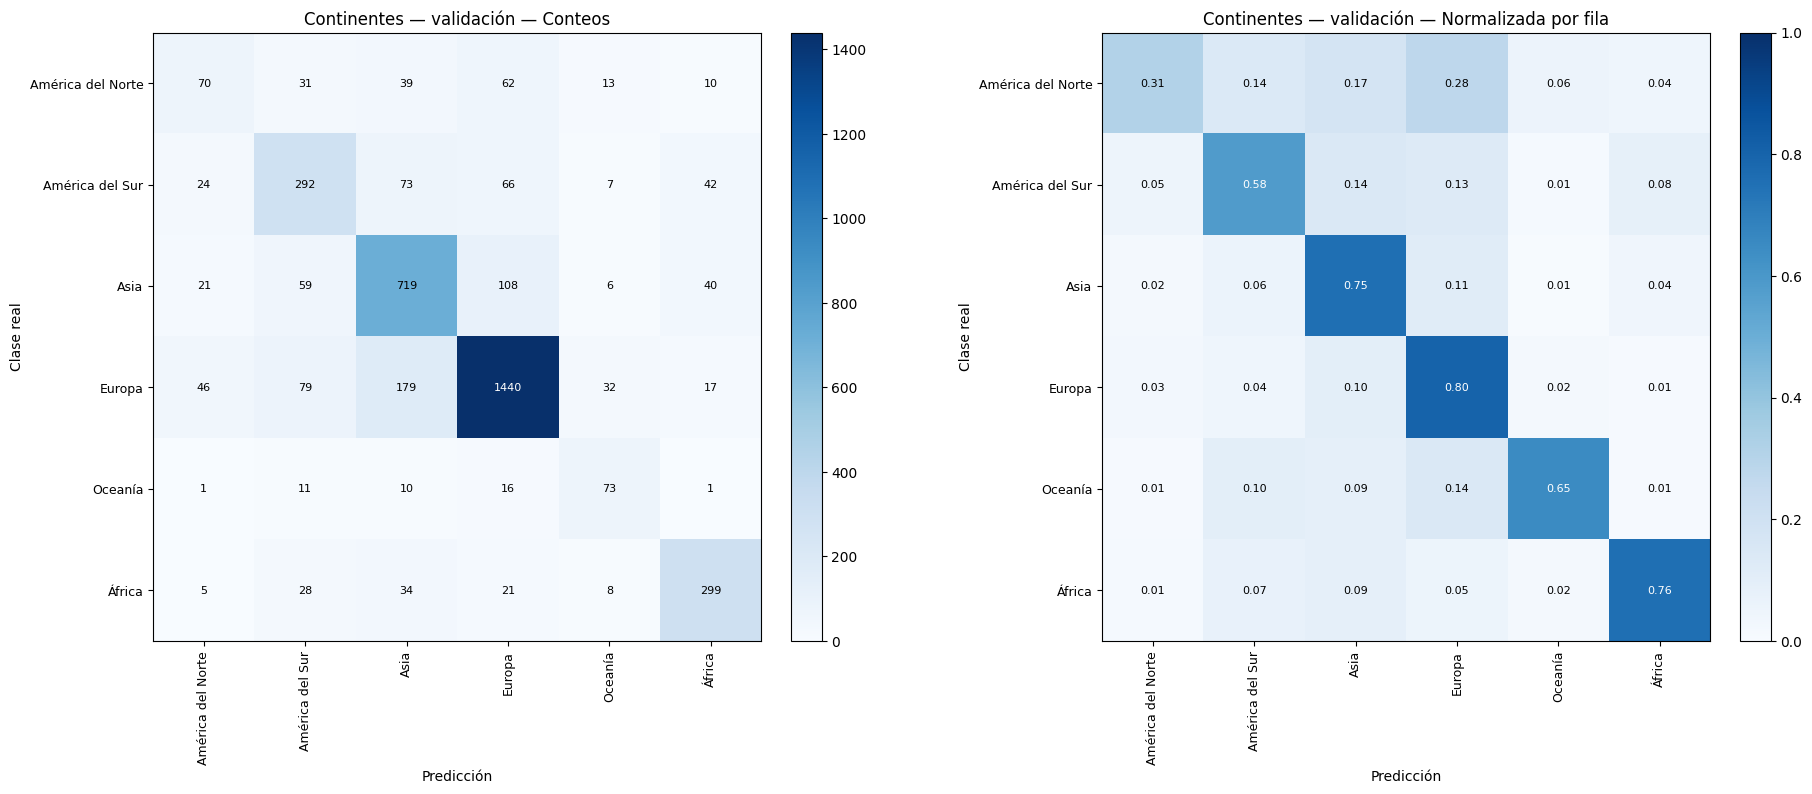

In [ ]:
def mostrar_matriz(tabla, titulo, nombre, anotar=False):
    valores = tabla.to_numpy()
    normalizada = np.divide(valores, valores.sum(axis=1, keepdims=True),
                            out=np.zeros_like(valores, dtype=float),
                            where=valores.sum(axis=1, keepdims=True) != 0)
    tabla.to_csv(ruta_resultados / f"{nombre}.csv")
    pd.DataFrame(normalizada, index=tabla.index, columns=tabla.columns).to_csv(
        ruta_resultados / f"{nombre}_normalizada.csv")
    grande = max(tabla.shape) > 30
    fig, axes = plt.subplots(1, 2, figsize=(32, 15) if grande else (19, 8))
    for ax, matriz, subtitulo, formato in zip(
            axes, [valores, normalizada], ["Conteos", "Normalizada por fila"], ["d", ".2f"]):
        grafico = ax.imshow(matriz, cmap="Blues", vmin=0, vmax=1 if subtitulo.startswith("Normalizada") else None)
        ax.set_xticks(range(len(tabla.columns)), tabla.columns, rotation=90, fontsize=7 if grande else 9)
        ax.set_yticks(range(len(tabla.index)), tabla.index, fontsize=7 if grande else 9)
        ax.set(xlabel="Predicción", ylabel="Clase real", title=f"{titulo} — {subtitulo}")
        if anotar:
            umbral = matriz.max() / 2
            for i in range(matriz.shape[0]):
                for j in range(matriz.shape[1]):
                    ax.text(j, i, format(matriz[i, j], formato), ha="center", va="center",
                            color="white" if matriz[i, j] > umbral else "black", fontsize=8)
        fig.colorbar(grafico, ax=ax, fraction=0.046, pad=0.04)
    fig.tight_layout()
    fig.savefig(ruta_resultados / f"{nombre}.png", dpi=160)
    plt.show()

cm_paises = pd.DataFrame(confusion_matrix(y_true, y_pred, labels=range(len(paises))),
                         index=paises, columns=paises)
mostrar_matriz(cm_paises, "Países — validación", "confusion_paises")
cm_continentes = pd.DataFrame(confusion_matrix(
    predicciones["continente_real"], predicciones["continente_predicho"], labels=continentes),
    index=continentes, columns=continentes)
mostrar_matriz(cm_continentes, "Continentes — validación", "confusion_continentes", anotar=True)

### Matrices de países por continente

Cada matriz usa todas las imágenes cuyo continente **real** es el indicado.
La columna «Otro continente» conserva los errores hacia países fuera de ese
continente, para no inflar las métricas al descartarlos. Cada fila normalizada
suma uno cuando hay ejemplos de ese país en validación.

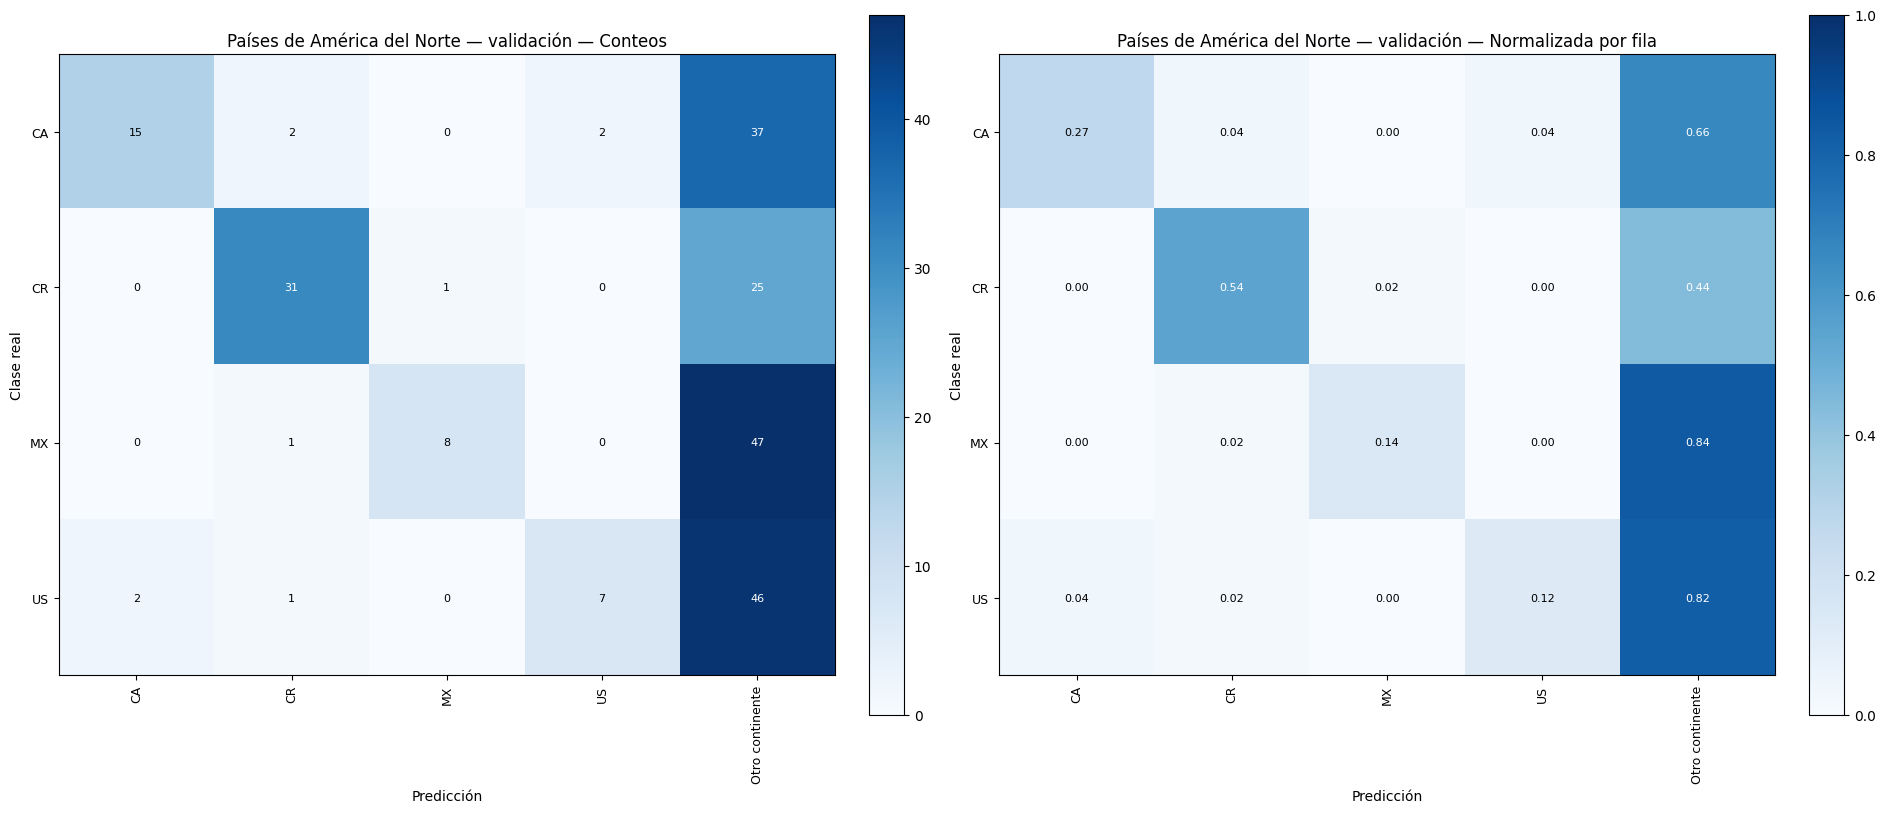

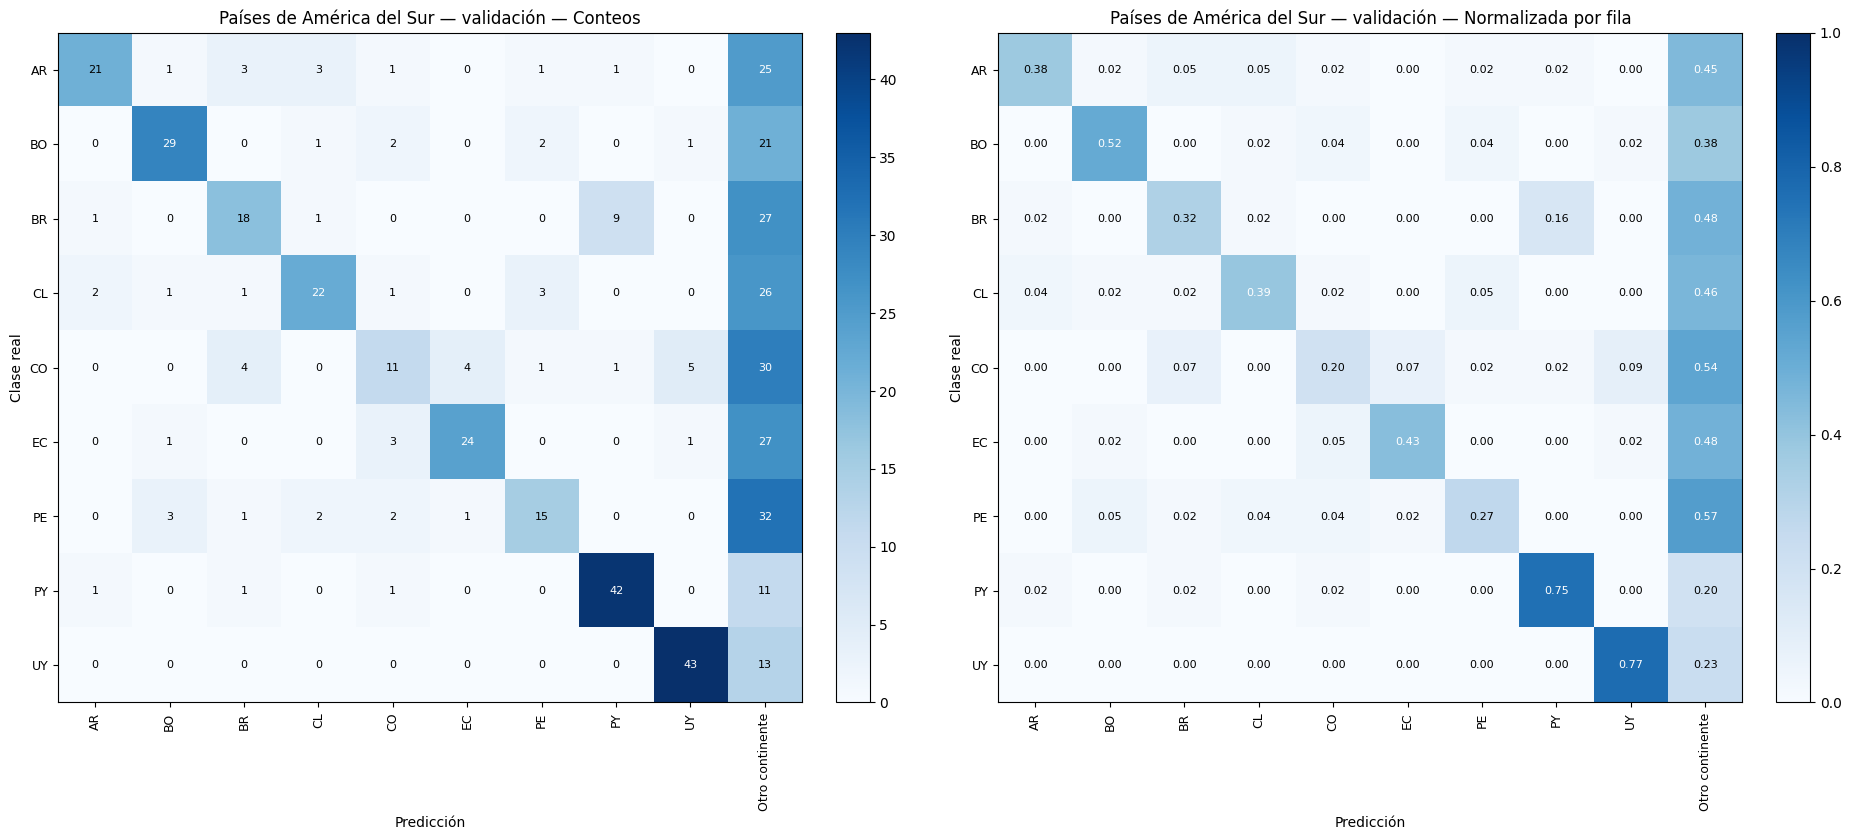

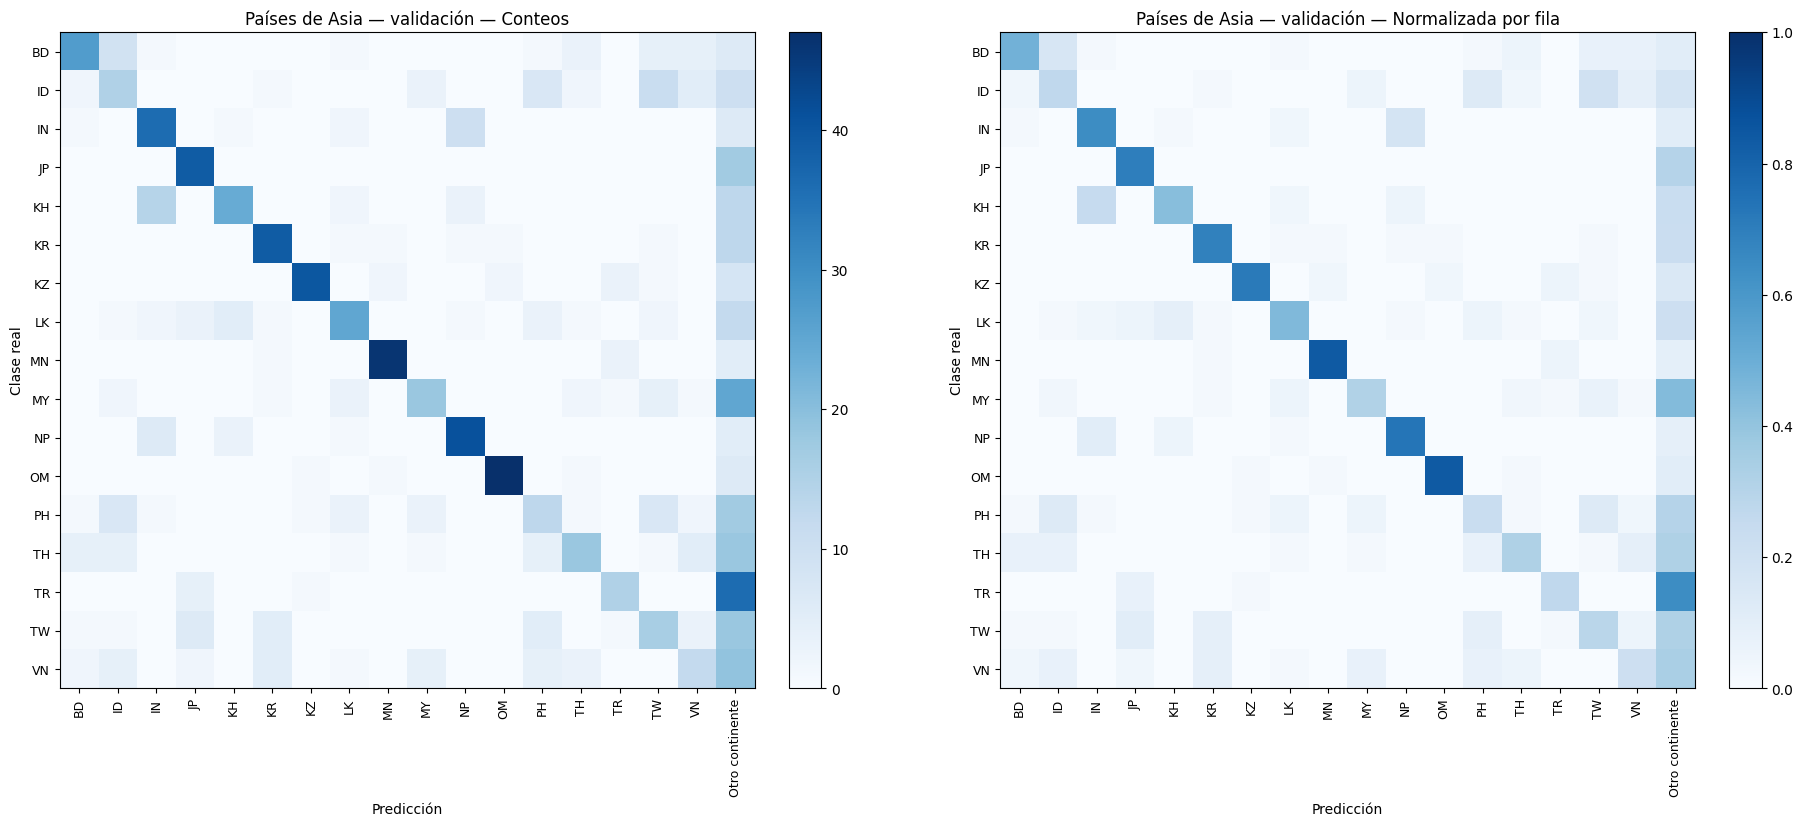

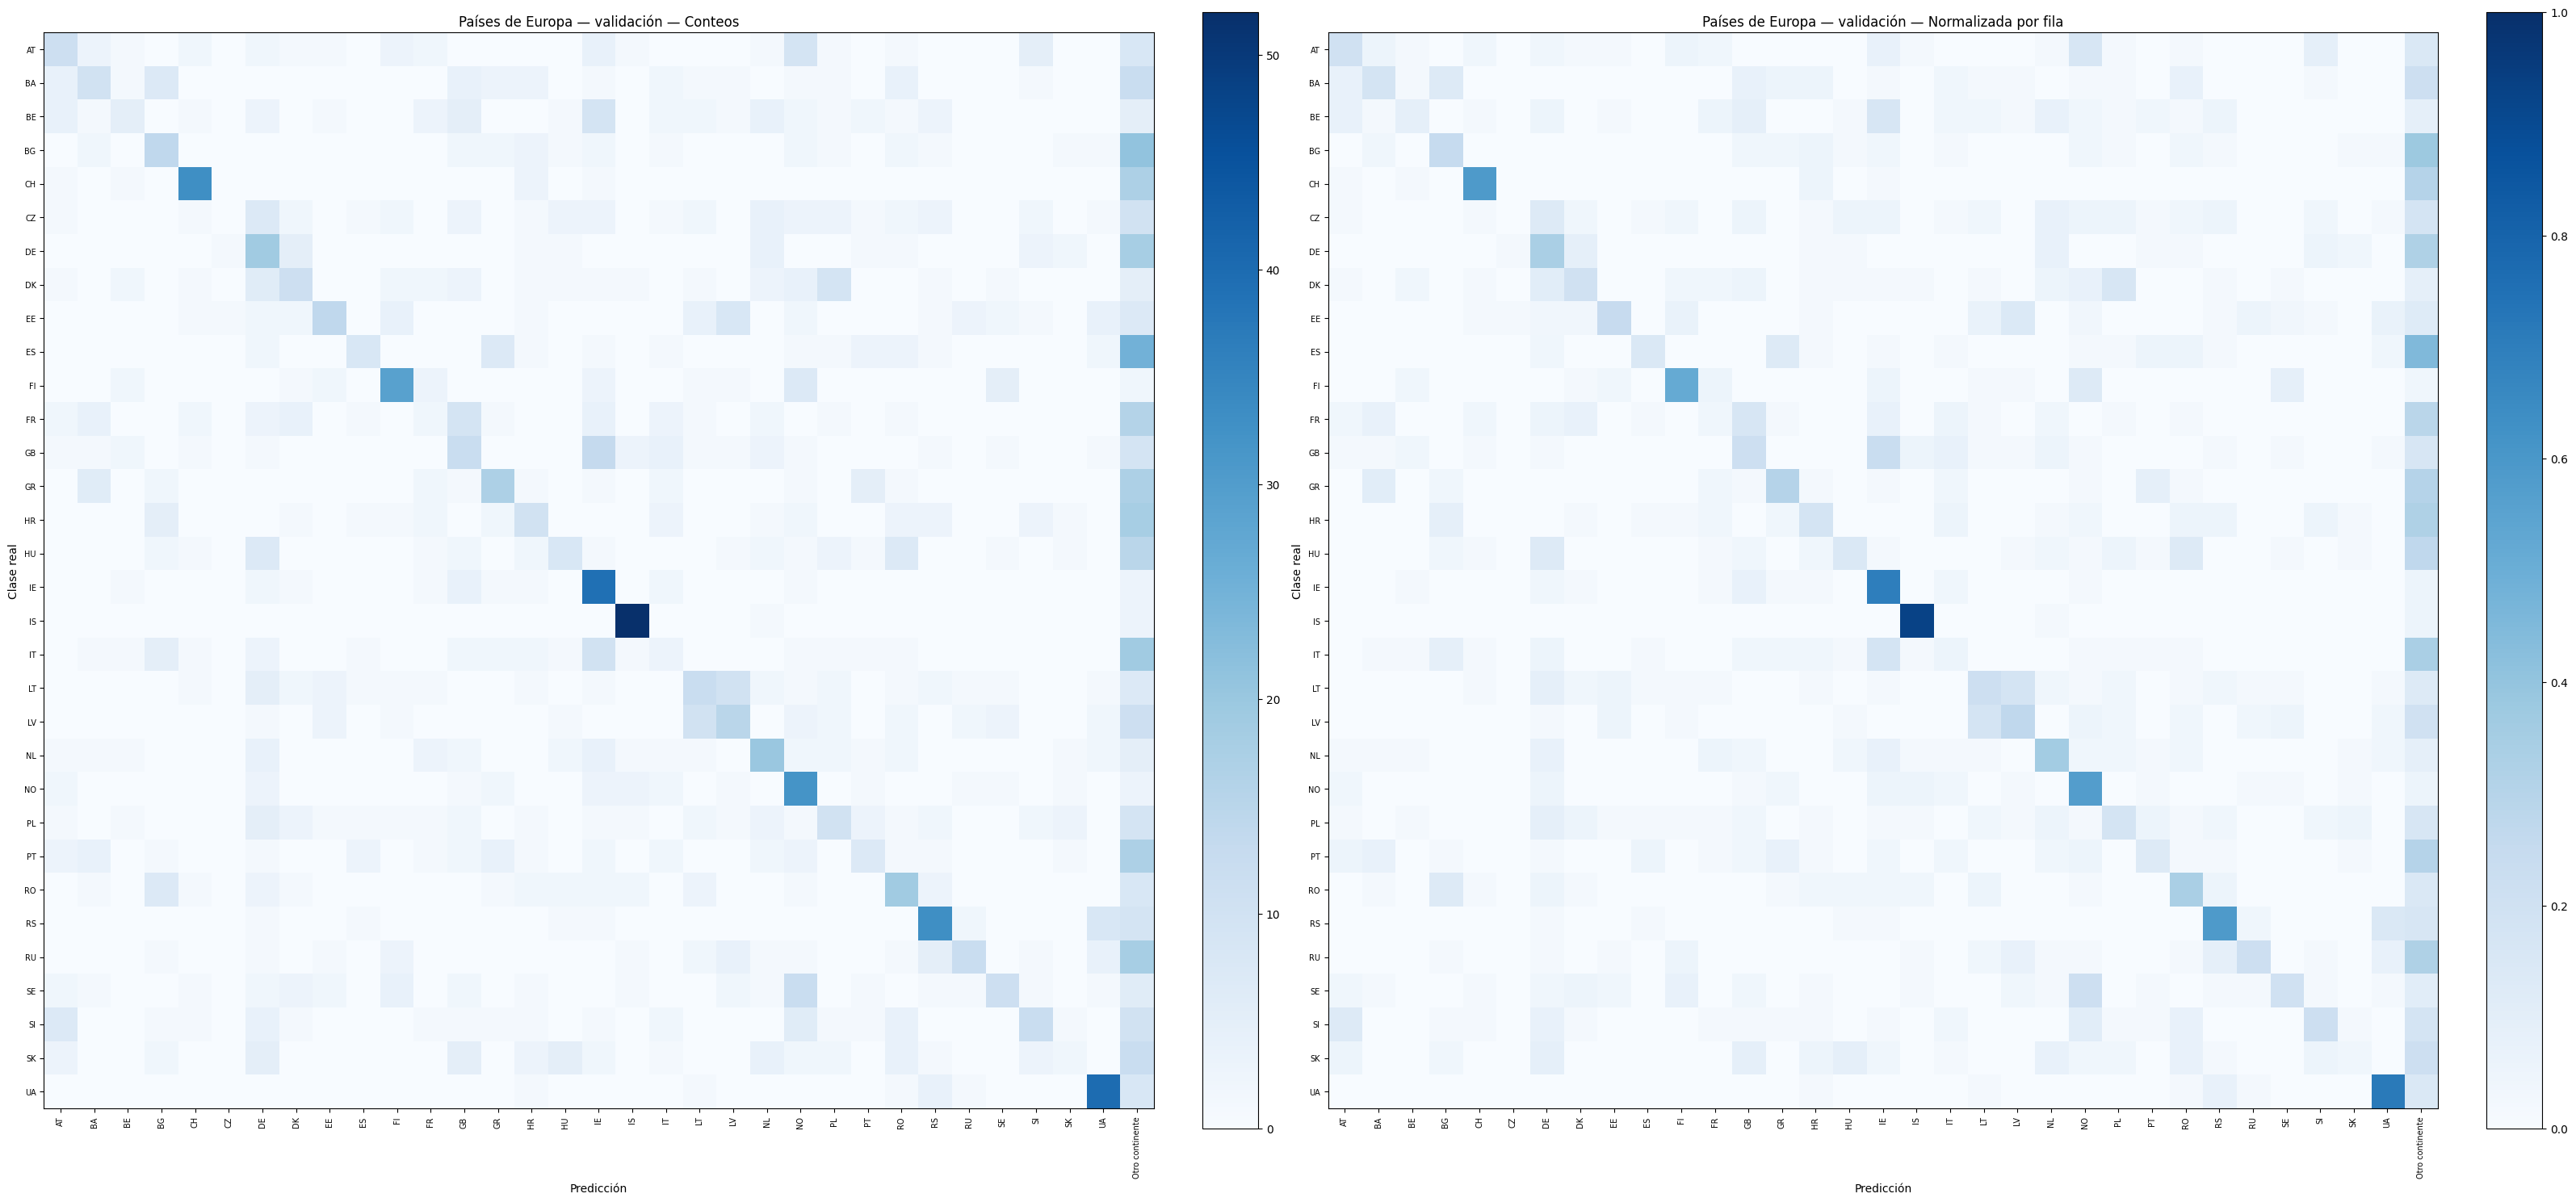

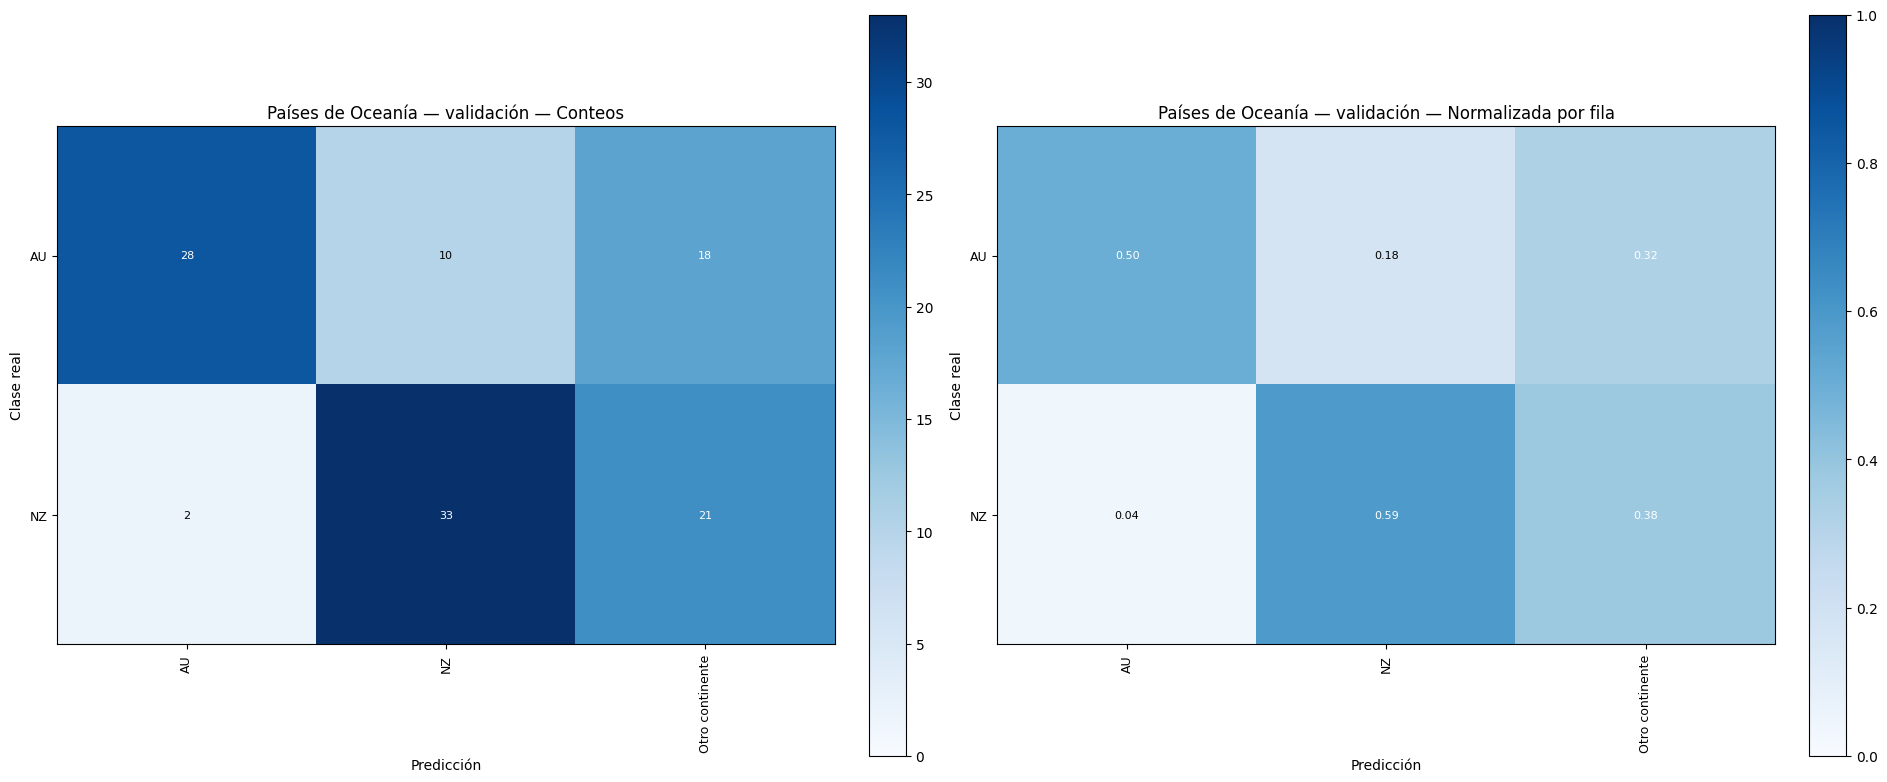

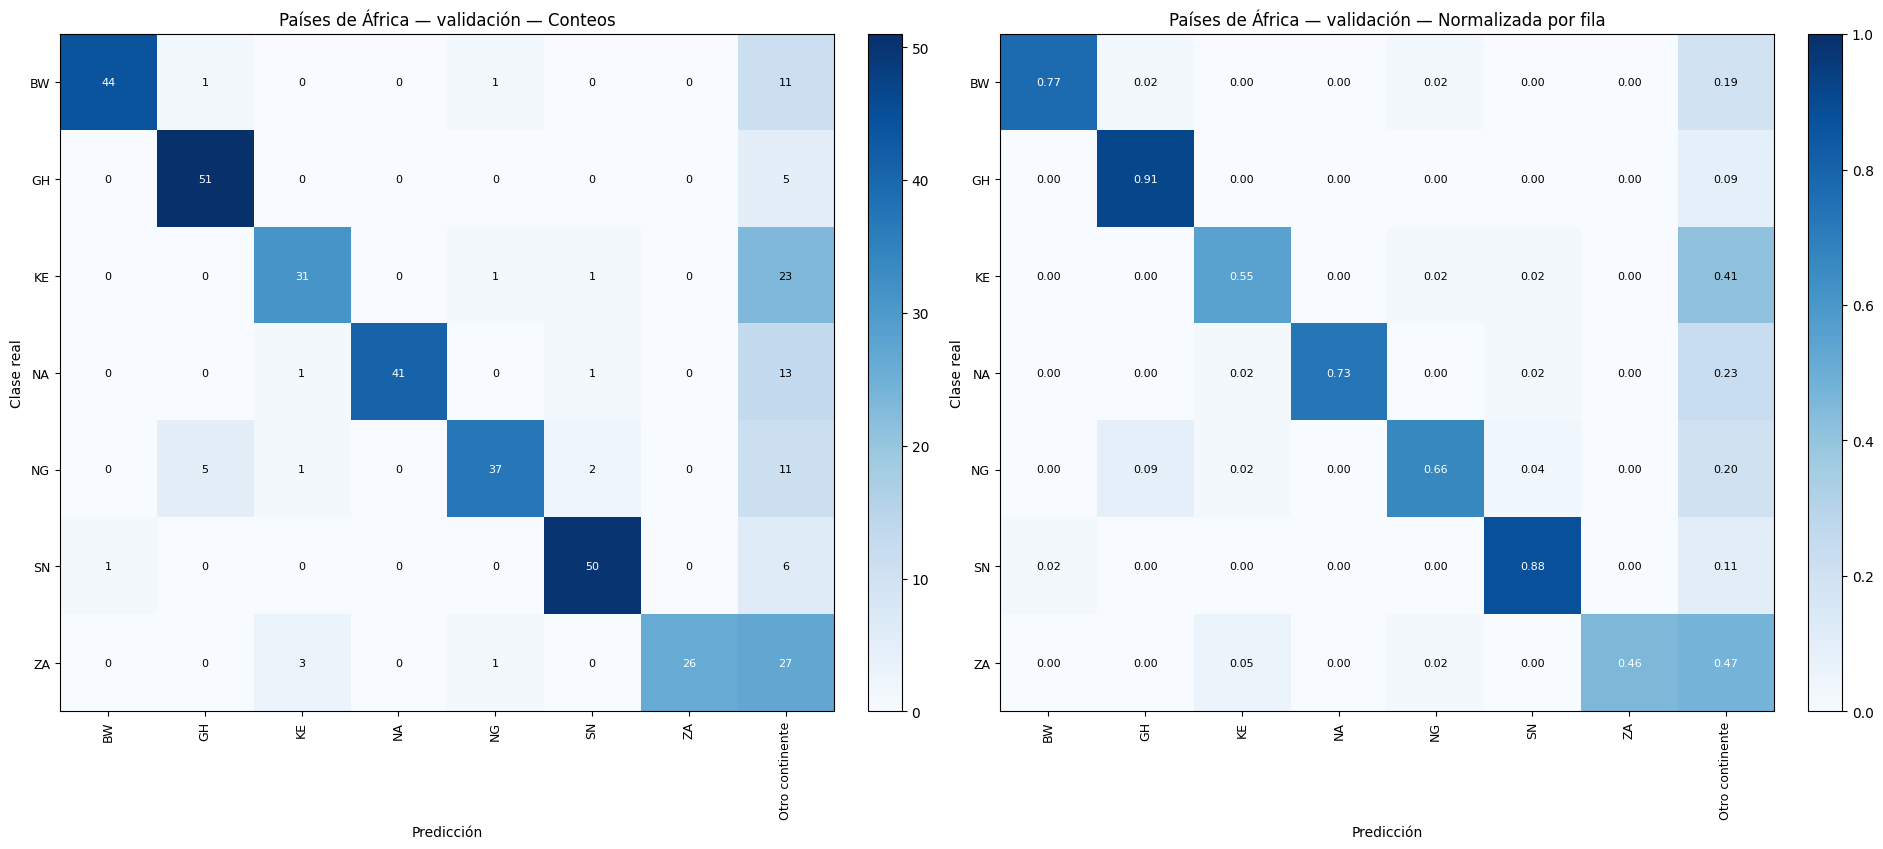

Métricas, predicciones y figuras guardadas en c:\Users\jurad\Documents\facultad\rrnn2\tp-final\geo-project\outputs\resnet18_50k\20261019_112821_798407


In [ ]:
for i, continente in enumerate(continentes):
    codigos = [p for p in paises if pais_a_continente[p] == continente]
    subset = predicciones.loc[predicciones["continente_real"] == continente].copy()
    subset["prediccion_agrupada"] = subset["pais_predicho"].where(
        subset["pais_predicho"].isin(codigos), "Otro continente")
    tabla = pd.crosstab(subset["pais_real"], subset["prediccion_agrupada"]).reindex(
        index=codigos, columns=[*codigos, "Otro continente"], fill_value=0)
    assert tabla.to_numpy().sum() == len(subset)
    mostrar_matriz(tabla, f"Países de {continente} — validación",
                   f"confusion_paises_continente_{i + 1}", anotar=len(codigos) <= 12)
print(f"Métricas, predicciones y figuras guardadas en {ruta_resultados}")